**Auteur :** NOYON Nicolas — M2 Énergie. Partie 1 (indice Niño3.4) faite en binôme avec ALHOUSSEIN BEN Ali le 3 novembre 2026 (cellules et résultats repris ci-dessous) ; partie 2 (groupe vent) faite seul le 16 novembre 2026.

# ERA5 practical 4 — ENSO and the solar and wind resources at La Réunion

**Foundations of climate change: basics and impacts — Master's in Energy, M2 — ENERGY-Lab, Université de La Réunion**

**Question:** does ENSO (El Niño and La Niña) change the solar and wind resources of La Réunion, and by how much? Solar for everyone; wind as a bonus.

**Workflow.** The same processing chain is applied twice: *raw monthly data → anomalies → (trend removed) → spatial mean → seasonal mean (DJF) → standardised index / resource series → comparison*.
* **Part 1**: chain A, the index. You build Niño3.4 from raw sea surface temperature (SST), checking each step, then you write your hypothesis.
* **Part 2**: chain B, the resource. You apply the same steps to the solar irradiation, averaged over a box around La Réunion and Mauritius, and compare it with your index. Two groups work on the solar irradiation, two groups on the 100 m wind speed: same steps, different variable.

The workflow table and the instructions are in the PDF sheet.

Before you start: *File → Save a copy in Drive*. Three files must be in your Google Drive (*My Drive*): `ERA5_TP2.zip` (practical 2), `mon_gl_sstg_1979-2001.nc` and `mon_gl_sstg_2002-2024.nc` (global SST, two files) and `nino34.long.anom.csv` (NOAA Niño3.4 index, to check yours).

## Set-up (run the two cells, in order)

In [1]:
import os, glob, zipfile, warnings
import numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings('ignore')

try:                                            # Google Colab: mount the Drive
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = '/content/drive/MyDrive'
except ImportError:                             # elsewhere: folder given by ERA5_ROOT, or the current folder
    ROOT = os.environ.get('ERA5_ROOT', '.')

def _first(patterns):
    for p in patterns:
        hits = sorted(glob.glob(p))
        if hits:
            return hits[0]
    return None

DATA = os.environ.get('ERA5_DATA')
if not DATA:
    archive = _first([f'{ROOT}/ERA5_TP2*.zip', f'{ROOT}/*/ERA5_TP2*.zip'])
    if archive is None:
        raise FileNotFoundError('ERA5_TP2.zip not found: put it at the top level of your Drive (My Drive).')
    DATA = '/content/era5' if os.path.isdir('/content') else os.path.abspath('era5_data')
    if not glob.glob(f'{DATA}/**/*.nc', recursive=True):
        zipfile.ZipFile(archive).extractall(DATA)
print(len(glob.glob(f'{DATA}/**/*.nc', recursive=True)), 'NetCDF files found')


INDICES = None
NOAA_NINO = os.environ.get('ERA5_NOAA') or _first([f'{ROOT}/nino34*.csv', f'{ROOT}/*nino34*.csv', f'{ROOT}/*/nino34*.csv', f'{ROOT}/*/*nino34*.csv'])
if NOAA_NINO is None:
    raise FileNotFoundError('nino34.long.anom.csv (NOAA) not found: put it in your Drive (My Drive).')
print('NOAA Niño3.4 file:', os.path.basename(NOAA_NINO))

SST_FILES = sorted(set(glob.glob(f'{ROOT}/mon_gl_sstg*.nc') + glob.glob(f'{ROOT}/*/mon_gl_sstg*.nc')
                       + glob.glob(f'{ROOT}/*/*/mon_gl_sstg*.nc') + glob.glob(f'{DATA}/**/mon_gl_sstg*.nc', recursive=True)))
if not SST_FILES:
    raise FileNotFoundError('mon_gl_sstg_1979-2001.nc and mon_gl_sstg_2002-2024.nc not found: put them in your Drive (My Drive).')
print('SST file(s):', [os.path.basename(f) for f in SST_FILES])

Mounted at /content/drive
35 NetCDF files found
NOAA Niño3.4 file: nino34.long.anom.csv
SST file(s): ['mon_gl_sstg_1979-2001.nc', 'mon_gl_sstg_2002-2024.nc']


**Toolbox.**
*Chain A (index):* `open_sst()` · `climatology(da)` · `anomalies(da)` · `linear_trend(da)` · `remove_trend(da)` · `area_mean(da, **NINO34)` · `plot_global(fields, titles, levels, cmap, label)` · `load_noaa()`
*Chain B (resource):* `open_monthly(pattern, var)` · `anomalies(da)` · `linear_trend(da)` · `remove_trend(da)` · `area_mean(da, **MASC)` (La Réunion-Mauritius box) · `at(da, 'La Réunion')` · `seasonal(da, 'DJF')` · `phase_years(nino)` · `corr(a, b)` · `r_threshold(n)` · `composite(field, pos, neg)` · `plot_bars(...)` · `plot_maps(...)` · `wind_cf(speed)` (bonus)

Type `help(linear_trend)` to read the description of a tool.

In [2]:
CLIM = ('1991-01-01', '2020-12-31')
SITES = {'La Réunion': (-21.1, 55.5), 'Mauritius': (-20.2, 57.5), 'Antananarivo': (-18.9, 47.5),
         'Toliara': (-23.35, 43.7), 'Maputo': (-25.97, 32.6), 'Johannesburg': (-26.2, 28.05)}
SEASONS = {'DJF': [12, 1, 2], 'MAM': [3, 4, 5], 'JJA': [6, 7, 8], 'SON': [9, 10, 11]}

def _std(ds):
    ren = {k: v for k, v in {'valid_time': 'time', 'latitude': 'lat', 'longitude': 'lon'}.items() if k in ds.dims or k in ds.coords}
    ds = ds.rename(ren).drop_vars([c for c in ('number', 'expver') if c in ds.coords], errors='ignore')
    return ds.sortby('lat').sortby('lon')

def open_monthly(pattern, var=None):
    """Open all the monthly files matching `pattern` and keep 1991-2020 (one value per month)."""
    files = sorted(glob.glob(f'{DATA}/**/{pattern}', recursive=True))
    if not files:
        raise FileNotFoundError(f'No file matches {pattern}')
    parts = []
    for f in files:
        ds = _std(xr.open_dataset(f))
        name = var or [v for v in ds.data_vars if ds[v].ndim >= 3][0]
        da = ds[name].sel(time=slice(*CLIM))
        if da.sizes['time']:
            parts.append(da.load())
    da = xr.concat(parts, 'time').sortby('time')
    start = pd.to_datetime({'year': da.time.dt.year.values, 'month': da.time.dt.month.values, 'day': 1})
    da = da.assign_coords(time=start.values, lat=da.lat.round(3), lon=da.lon.round(3))
    da = da.isel(time=~da.get_index('time').duplicated())
    da.attrs = {}
    return da

def at(da, site):
    """Value at the grid point nearest to one of the SITES."""
    lat, lon = SITES[site]
    return da.sel(lat=lat, lon=lon, method='nearest')

def climatology(da, ref=CLIM):
    """Mean of each calendar month over the reference period 1991-2020 (12 values per point)."""
    return da.sel(time=slice(*ref)).groupby('time.month').mean('time')

def anomalies(da, ref=CLIM):
    """Remove from each month the 1991-2020 mean of the same calendar month."""
    out = da.groupby('time.month') - climatology(da, ref)
    return out.drop_vars('month', errors='ignore')

def seasonal(da, season):
    """One value per year: the mean of the 3 months of the season. DJF 1997-98 is labelled 1998."""
    m = SEASONS[season]
    da = da.sel(time=da.time.dt.month.isin(m))
    year = (da.time.dt.year + (da.time.dt.month == 12)) if season == 'DJF' else da.time.dt.year
    year = year.rename('year')
    out = da.groupby(year).mean('time')
    count = da.time.dt.month.groupby(year).count()
    return out.sel(year=count.year[count == 3].values)

def load_indices():
    """Monthly climate indices (standardised): idx.nino34, idx.dmi, idx.siod."""
    df = pd.read_csv(INDICES, parse_dates=[0], index_col=0)
    clean = lambda c: ''.join(ch for ch in c.lower().replace('ñ', 'n') if ch.isalnum())
    df.columns = [clean(c) for c in df.columns]
    df.index = df.index.to_period('M').to_timestamp()
    return xr.Dataset({c: ('time', df[c].values.astype(float)) for c in df.columns}, coords={'time': df.index.values})

def standardise(ix):
    return (ix - ix.mean()) / ix.std()

def phase_years(index_years, threshold=1.0):
    """Years where the (standardised) seasonal index is above +threshold, and below -threshold."""
    z = standardise(index_years)
    return [int(y) for y in z.year[z >= threshold].values], [int(y) for y in z.year[z <= -threshold].values]

def composite(field_years, pos, neg):
    """Mean of the `pos` years minus mean of the `neg` years, and a True/False map: significant at 5 % (Welch t-test)."""
    a, b = field_years.sel(year=pos), field_years.sel(year=neg)
    diff = a.mean('year') - b.mean('year')
    p = stats.ttest_ind(a.values, b.values, axis=0, equal_var=False).pvalue
    return diff, xr.DataArray(p < 0.05, dims=diff.dims, coords=diff.coords)

def corr(a, b):
    a, b = xr.align(a, b)
    return float(xr.corr(a, b))

def r_threshold(n, alpha=0.05):
    """Smallest |r| that is significant at 5 % with n independent values."""
    t = stats.t.ppf(1 - alpha / 2, n - 2)
    return float(t / np.sqrt(t ** 2 + n - 2))

def lag_corr(index_monthly, series_monthly, lags=range(0, 10)):
    """r between the index in month t and the series in month t + lag (lag in months)."""
    i, s = index_monthly.to_series(), series_monthly.to_series()
    return pd.Series({k: i.corr(s.shift(-k)) for k in lags}, name='r')

def box_mean(da, lat, lon, ocean_only=True):
    """Mean over a lat/lon box, e.g. box_mean(t2m, (-10, 10), (50, 100))."""
    sub = da.sel(lat=slice(*lat), lon=slice(*lon))
    if ocean_only:
        sub = sub.where(LSM.sel(lat=slice(*lat), lon=slice(*lon)) < 0.5)
    return sub.mean(['lat', 'lon'])

def wind_cf(speed, k=2.0):
    """Approximate capacity factor of a generic turbine (cut-in 3, rated 12, cut-out 25 m/s), Weibull winds of shape k around the mean speed."""
    from math import gamma
    _trap = getattr(np, 'trapezoid', None) or getattr(np, 'trapz')
    v = np.linspace(0, 40, 401)
    p = np.where((v >= 3) & (v < 12), (v ** 3 - 27) / (12 ** 3 - 27), 0.0) + np.where((v >= 12) & (v < 25), 1.0, 0.0)
    def cf(m):
        if not np.isfinite(m) or m <= 0:
            return np.nan
        c = m / gamma(1 + 1 / k)
        f = (k / c) * (v / c) ** (k - 1) * np.exp(-(v / c) ** k)
        return float(_trap(p * f, v))
    return xr.apply_ufunc(np.vectorize(cf), speed)

def plot_bars(values, index_years, title, ylabel, threshold=1.0):
    """One bar per year (left axis: the values); colour = phase of the index (red El Niño, blue La Niña, grey neutral); black line = the index itself (right axis)."""
    pos, neg = phase_years(index_years, threshold)
    v = values.to_series()
    col = ['#c0392b' if y in pos else '#2471a3' if y in neg else '#b3b6b7' for y in v.index]
    fig, ax = plt.subplots(figsize=(11, 3.4), constrained_layout=True)
    ax.bar(v.index, v.values, color=col); ax.axhline(0, color='k', lw=0.8)
    ax.set_title(title, loc='left'); ax.set_ylabel(ylabel)
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color='#c0392b', label=f'El Niño year (index ≥ +{threshold:g} σ)'), Patch(color='#2471a3', label=f'La Niña year (index ≤ −{threshold:g} σ)'),
                       Patch(color='#b3b6b7', label='neutral year')], loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=9, frameon=False,
              title='Colour = phase of the DJF Niño3.4 index')
    ix = index_years.to_series()
    ax2 = ax.twinx(); ax2.plot(ix.index, ix.values, color='k', lw=1.2, marker='o', ms=3)
    ax2.set_ylabel('Niño3.4, DJF (σ) — black line'); lim = max(abs(ix.values)) * 1.1; ax2.set_ylim(-lim, lim)
    lim1 = max(abs(v.values)) * 1.1; ax.set_ylim(-lim1, lim1)
    return fig

def plot_maps(fields, titles, levels, cmap='PuOr_r', label='', dots=None, extend='both', ncols=2):
    """Maps side by side, coastline from the land-sea mask, star at La Réunion, dots where `dots` is True."""
    n = len(fields); ncols = min(ncols, n); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.2 * ncols, 4.2 * nrows), constrained_layout=True, squeeze=False)
    for i, (f, t) in enumerate(zip(fields, titles)):
        ax = axes.flat[i]
        im = ax.contourf(f.lon, f.lat, f, levels=levels, cmap=cmap, extend=extend)
        ax.contour(LSM.lon, LSM.lat, LSM, levels=[0.5], colors='k', linewidths=0.6)
        if dots is not None and dots[i] is not None:
            d = dots[i].where(dots[i]).stack(p=('lat', 'lon')).dropna('p')
            ax.scatter(d.lon[::3], d.lat[::3], s=1.5, c='k')
        ax.plot(55.5, -21.1, marker='*', color='k', ms=11, mfc='yellow')
        ax.plot([55, 58, 58, 55, 55], [-22, -22, -19.5, -19.5, -22], color='k', lw=1.4, ls='--')
        ax.set_title(t, loc='left', fontsize=11); ax.set_aspect('equal')
    for ax in list(axes.flat)[n:]:
        ax.set_visible(False)
    fig.colorbar(im, ax=axes, shrink=0.85, label=label)
    return fig

LSM = _std(xr.open_dataset(sorted(glob.glob(f'{DATA}/**/*lsm*.nc', recursive=True))[0]))
LSM = LSM[[v for v in LSM.data_vars][0]].squeeze(drop=True).load()
LSM = LSM.assign_coords(lat=LSM.lat.round(3), lon=LSM.lon.round(3))
NINO34 = dict(lat=(-5, 5), lon=(190, 240))          # 5°S-5°N, 170°W-120°W in longitudes 0-360

def open_sst():
    """Global monthly sea surface temperature, 1979-2024, in °C, longitudes 0-360."""
    parts = [_std(xr.open_dataset(f)) for f in SST_FILES]
    ds = xr.concat(parts, 'time') if len(parts) > 1 else parts[0]
    name = 'sst' if 'sst' in ds else [v for v in ds.data_vars if ds[v].ndim >= 3][0]
    da = ds[name].load()
    da = da.assign_coords(lon=(da.lon % 360).round(3), lat=da.lat.round(3)).sortby('lon').sortby('lat')
    start = pd.to_datetime({'year': da.time.dt.year.values, 'month': da.time.dt.month.values, 'day': 1})
    da = da.assign_coords(time=start.values)
    da = da.isel(time=~da.get_index('time').duplicated())
    if float(da.mean()) > 200:
        da = da - 273.15
    da.attrs = {}
    return da

def area_mean(da, lat, lon, weighted=True):
    """Mean over a lat/lon box (lon in 0-360). weighted=True: each grid cell counts in proportion to its area, cos(latitude)."""
    sub = da.sel(lat=slice(*lat), lon=slice(*lon))
    if weighted:
        return sub.weighted(np.cos(np.deg2rad(sub.lat))).mean(('lat', 'lon'))
    return sub.mean(('lat', 'lon'))

def _years(da):
    t = (da.time.dt.year + (da.time.dt.month - 1) / 12).astype(float)
    return t - t.mean()

def linear_trend(da):
    """Least-squares slope of a series (or of each grid point), in units per YEAR."""
    t = _years(da)
    return ((da - da.mean('time')) * t).sum('time', skipna=False) / (t ** 2).sum()

def remove_trend(da):
    """The series (or field) minus its least-squares linear trend."""
    return da - linear_trend(da) * _years(da)

def plot_global(fields, titles, levels, cmap='RdBu_r', label='', lon=(30, 300), lat=(-40, 40)):
    """SST maps, one under the other; black box: Niño3.4; star: La Réunion. Land is grey."""
    fig, axes = plt.subplots(len(fields), 1, figsize=(12, 3.6 * len(fields)), constrained_layout=True, squeeze=False)
    for ax, f, t in zip(axes.flat, fields, titles):
        f = f.sel(lon=slice(*lon), lat=slice(*lat))
        ax.set_facecolor('0.8')
        im = ax.contourf(f.lon, f.lat, f, levels=levels, cmap=cmap, extend='both')
        ax.plot([190, 240, 240, 190, 190], [-5, -5, 5, 5, -5], color='k', lw=1.8)
        ax.plot(55.5, -21.1, marker='*', color='k', ms=11, mfc='yellow')
        ax.set_title(t, loc='left', fontsize=11); ax.set_aspect('equal')
        ax.set_xticks(range(lon[0], lon[1] + 1, 30)); ax.set_xticklabels([f'{x}°E' if x <= 180 else f'{360 - x}°W' for x in range(lon[0], lon[1] + 1, 30)])
    fig.colorbar(im, ax=axes, shrink=0.9, label=label)
    return fig

def load_noaa():
    """NOAA PSL Niño3.4 index from HadISST1.1: monthly anomaly in °C relative to 1981-2010, trend NOT removed. Missing values become NaN."""
    df = pd.read_csv(NOAA_NINO, skiprows=1, header=None, usecols=[0, 1], names=['time', 'nino34'], skipinitialspace=True)
    df['time'] = pd.to_datetime(df['time'], errors='coerce')
    df['nino34'] = pd.to_numeric(df['nino34'], errors='coerce')
    df = df.dropna(subset=['time']).set_index('time')
    df.loc[df['nino34'] < -90, 'nino34'] = np.nan
    return df['nino34'].to_xarray()

MASC = dict(lat=(-22, -19.5), lon=(55, 58))          # La Réunion-Mauritius box, 19.5-22°S, 55-58°E (dashed on the maps)
print('Toolbox ready.')

Toolbox ready.


## Example

In [3]:
sst = open_sst()                                # °C, 1979-2024, longitudes 0-360
print(sst.sizes)
print('Mean SST in the Niño3.4 box, January 1998:', round(float(area_mean(sst.sel(time='1998-01-01'), **NINO34)), 2), '°C')

Frozen({'time': 552, 'lat': 181, 'lon': 360})
Mean SST in the Niño3.4 box, January 1998: 29.13 °C


## Part 1, step 1 — Raw SST maps

{'time': 552, 'lat': 181, 'lon': 360}
SST, tout le globe   : -3.32 à 36.26 °C
SST, entre 40°S et 40°N : -1.48 à 36.26 °C


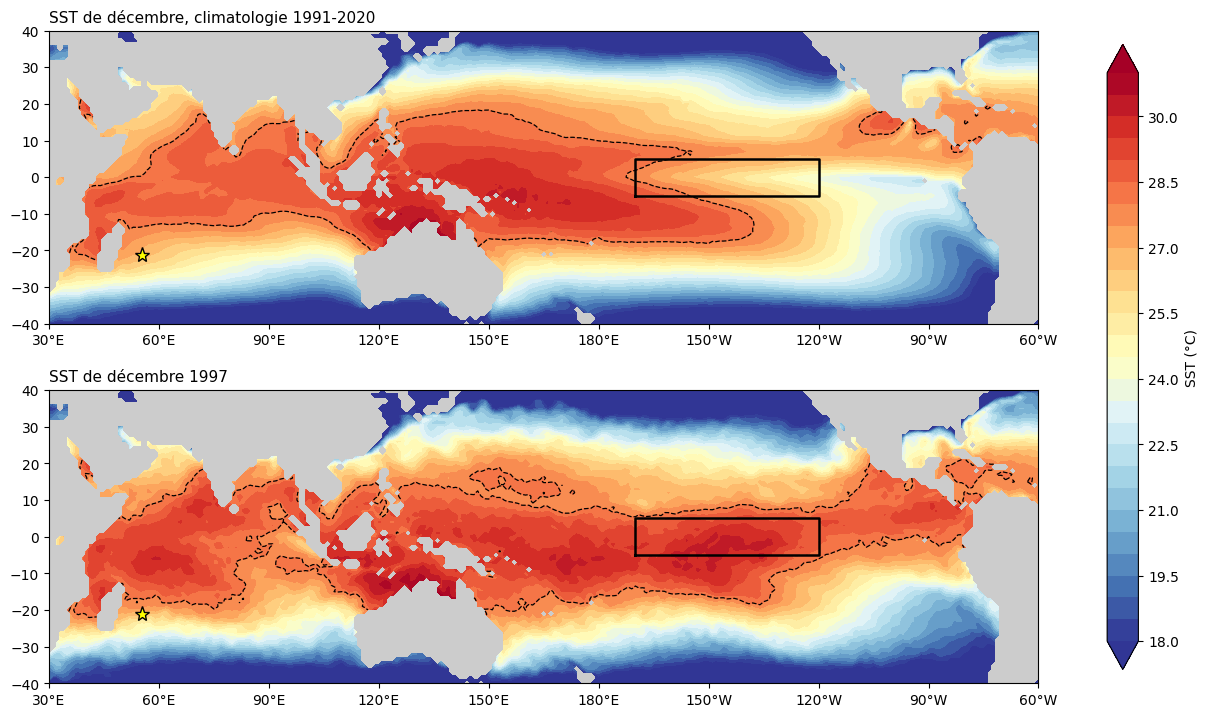

  climatologie : SST ≥ 28 °C sur l’équateur jusqu’à 194°E = 166°W ; part de la boîte Niño3.4 à ≥ 28 °C : 11 %
 décembre 1997 : SST ≥ 28 °C sur l’équateur jusqu’à 282°E = 78°W ; part de la boîte Niño3.4 à ≥ 28 °C : 100 %
Boîte Niño3.4 : décembre 1997 = 29.37 °C ; décembre de la climatologie = 26.63 °C ; différence = +2.73 °C


In [13]:
# 1.1 Ouvrir la SST et vérifier ce qu'on a ouvert
sst = open_sst()                                   # °C, 1979-2024, longitudes 0-360
print(dict(sst.sizes))
print('SST, tout le globe   :', round(float(sst.min()), 2), 'à', round(float(sst.max()), 2), '°C')
print('SST, entre 40°S et 40°N :', round(float(sst.sel(lat=slice(-40, 40)).min()), 2), 'à',
      round(float(sst.sel(lat=slice(-40, 40)).max()), 2), '°C')

# Décembre « normal » (climatologie 1991-2020) et décembre 1997
clim = climatology(sst)                            # 12 cartes, une par mois calendaire
dec_clim = clim.sel(month=12)
dec_1997 = sst.sel(time='1997-12-01')

fields = [dec_clim, dec_1997]
fig = plot_global(fields, ['SST de décembre, climatologie 1991-2020', 'SST de décembre 1997'],
                  levels=np.arange(18, 31.1, 0.5), cmap='RdYlBu_r', label='SST (°C)')
for ax, f in zip(fig.axes, fields):                # pointillés : isotherme 28 °C (bord de la warm pool)
    g = f.sel(lon=slice(30, 300), lat=slice(-40, 40))
    ax.contour(g.lon, g.lat, g, levels=[28], colors='k', linewidths=0.9, linestyles='--')
plt.show()

# 1.2 Jusqu'où va l'eau à plus de 28 °C le long de l'équateur (moyenne 5°S-5°N) ?
for name, f in [('climatologie', dec_clim), ('décembre 1997', dec_1997)]:
    eq = f.sel(lat=slice(-5, 5)).mean('lat').sel(lon=slice(120, 290))
    east = float(eq.lon.where(eq >= 28).max())
    inbox = f.sel(lat=slice(-5, 5), lon=slice(190, 240))
    print(f'{name:>14} : SST ≥ 28 °C sur l’équateur jusqu’à {east:.0f}°E = {360 - east:.0f}°W ; '
          f'part de la boîte Niño3.4 à ≥ 28 °C : {100 * float((inbox >= 28).mean()):.0f} %')

# 1.3 SST moyenne dans la boîte Niño3.4
b_1997 = float(area_mean(dec_1997, **NINO34))
b_clim = float(area_mean(dec_clim, **NINO34))
print(f'Boîte Niño3.4 : décembre 1997 = {b_1997:.2f} °C ; décembre de la climatologie = {b_clim:.2f} °C ; '
      f'différence = {b_1997 - b_clim:+.2f} °C')

*Checks and answers:*

* **Vérification.** Entre 40°S et 40°N, la SST va de −1,5 à 36,3 °C (maximum : golfe Persique en été) : on est bien en °C, pas en kelvins. Le minimum global (−3,3 °C) est un point isolé sous la banquise près de l'Antarctique, hors de la carte. Terres en gris ✓. La boîte va de 190 à 240°E, soit de 170°W à 120°W, entre 5°S et 5°N ✓.
* **Warm pool.** Les eaux les plus chaudes (plus de 28 °C, en pointillés ; jusqu'à 31 °C au nord de l'Australie) occupent le Pacifique ouest autour de l'Indonésie et de la Nouvelle-Guinée, et se prolongent sur l'océan Indien tropical. Sur l'équateur, l'eau à plus de 28 °C s'arrête vers 166°W. La boîte Niño3.4 est juste à l'est de la warm pool : elle est dans la transition vers la « langue froide » du Pacifique est (moins de 25 °C), où l'eau froide des profondeurs remonte le long de l'équateur et des côtes de l'Amérique du Sud.
* **Décembre 1997.** La langue froide a disparu : l'eau à plus de 28 °C couvre tout le Pacifique équatorial jusqu'aux côtes de l'Amérique du Sud (vers 78°W). Toute la boîte Niño3.4 dépasse 28 °C, contre 11 % de la boîte en décembre normal. La chaleur de la warm pool s'est étalée vers l'est : c'est El Niño.
* **Valeurs dans la boîte.** Décembre 1997 : 29,37 °C ; décembre moyen 1991–2020 : 26,63 °C ; différence : **+2,73 °C**.

## Part 1, step 2 — Climatology and anomalies

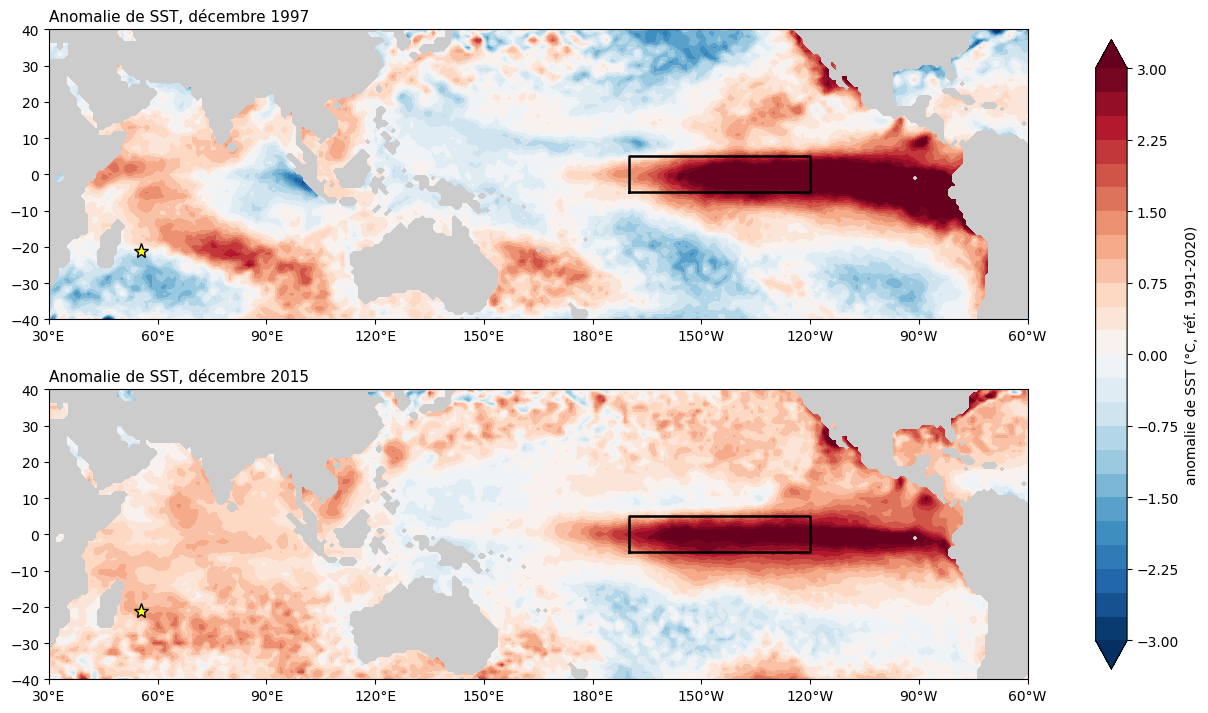

                                             1997-12  2015-12
Niño3.4                                         2.73     2.54
Pacifique ouest (5°S-5°N, 130-160°E)           -0.31    -0.14
Fer à cheval nord (15-30°N, 160°E-150°W)       -0.35     0.28
Fer à cheval sud (30-15°S, 180-130°W)          -0.57    -0.41
Pacifique nord-est (20-40°N, 160-120°W)        -0.28     0.66
Océan Indien ouest (10°S-10°N, 50-70°E)         0.80     0.66
Océan Indien est (10°S-0, 90-110°E)            -0.59     0.44
Océan Indien tropical (20°S-20°N, 40-100°E)     0.38     0.65
Autour de La Réunion (23-19°S, 53-58°E)        -0.22     1.03
1997-12 : anomalie maximale du Pacifique tropical = +6.2 °C, à 5°S et 82°W
2015-12 : anomalie maximale du Pacifique tropical = +3.9 °C, à 0°N et 109°W

|moyenne 1991-2020 des anomalies| : au plus 1.6e-05 °C, en moyenne 3.7e-06 °C (12 mois × tous les points)
Pour comparer, moyenne des anomalies 2021-2024 sur l’océan 60°S-60°N : +0.33 °C


In [14]:
# 2.1 Anomalies : on retire à chaque mois la moyenne 1991-2020 du même mois calendaire
sst_a = anomalies(sst)
fig = plot_global([sst_a.sel(time='1997-12-01'), sst_a.sel(time='2015-12-01')],
                  ['Anomalie de SST, décembre 1997', 'Anomalie de SST, décembre 2015'],
                  levels=np.arange(-3, 3.01, 0.25), cmap='RdBu_r', label='anomalie de SST (°C, réf. 1991-2020)')
plt.show()

# 2.2 Quelques moyennes régionales pour décrire les deux cartes (°C)
REGIONS = {'Niño3.4': NINO34,
           'Pacifique ouest (5°S-5°N, 130-160°E)': dict(lat=(-5, 5), lon=(130, 160)),
           'Fer à cheval nord (15-30°N, 160°E-150°W)': dict(lat=(15, 30), lon=(160, 210)),
           'Fer à cheval sud (30-15°S, 180-130°W)': dict(lat=(-30, -15), lon=(180, 230)),
           'Pacifique nord-est (20-40°N, 160-120°W)': dict(lat=(20, 40), lon=(200, 240)),
           'Océan Indien ouest (10°S-10°N, 50-70°E)': dict(lat=(-10, 10), lon=(50, 70)),
           'Océan Indien est (10°S-0, 90-110°E)': dict(lat=(-10, 0), lon=(90, 110)),
           'Océan Indien tropical (20°S-20°N, 40-100°E)': dict(lat=(-20, 20), lon=(40, 100)),
           'Autour de La Réunion (23-19°S, 53-58°E)': dict(lat=(-23, -19), lon=(53, 58))}
table = pd.DataFrame({t[:7]: {k: round(float(area_mean(sst_a.sel(time=t), **v)), 2) for k, v in REGIONS.items()}
                      for t in ['1997-12-01', '2015-12-01']})
print(table)
for t in ['1997-12-01', '2015-12-01']:
    pac = sst_a.sel(time=t).sel(lat=slice(-20, 20), lon=slice(150, 290))
    m = pac.where(pac == pac.max(), drop=True)
    la, lo = float(m.lat[0]), float(m.lon[0])
    print(f'{t[:7]} : anomalie maximale du Pacifique tropical = {float(pac.max()):+.1f} °C, '
          f'à {abs(la):.0f}°{"S" if la < 0 else "N"} et {360 - lo:.0f}°W')

# Vérification : moyenne des anomalies de chaque mois calendaire sur 1991-2020, en chaque point
check = sst_a.sel(time=slice(*CLIM)).groupby('time.month').mean('time')
print(f'\n|moyenne 1991-2020 des anomalies| : au plus {float(abs(check).max()):.1e} °C, '
      f'en moyenne {float(abs(check).mean()):.1e} °C (12 mois × tous les points)')
print(f'Pour comparer, moyenne des anomalies 2021-2024 sur l’océan 60°S-60°N : '
      f'{float(area_mean(sst_a.sel(time=slice("2021", "2024")), lat=(-60, 60), lon=(0, 359)).mean()):+.2f} °C')

*Checks and answers:*

* **Décembre 1997.** *Pacifique* : très forte anomalie chaude le long de l'équateur, de la ligne de changement de date jusqu'à l'Amérique du Sud : +2,7 °C en moyenne dans la boîte Niño3.4, plus de +6 °C au large de l'Équateur et du Pérou. Le Pacifique ouest est un peu froid (−0,3 °C), et ce froid s'étire vers le nord-est et le sud-est autour de la langue chaude (−0,35 et −0,6 °C) : c'est le « fer à cheval » froid typique d'El Niño. *Océan Indien* : un dipôle. Il fait chaud à l'ouest (+0,8 °C), avec une bande très chaude (+1,5 à +2,5 °C) qui part des Seychelles et file vers le sud-est, au nord-est des Mascareignes, jusqu'à 25–30°S, 85–100°E. Il fait froid à l'est, au large de Sumatra et de Java (−0,6 °C). C'est le dipôle de l'océan Indien (IOD) positif de 1997, qui accompagne El Niño. *Autour de La Réunion* : un peu plus froid que la normale (−0,2 °C), entre la bande chaude au nord-est et des eaux froides au sud-ouest.
* **Décembre 2015.** *Pacifique* : anomalie presque aussi forte dans la boîte (+2,5 °C), mais le maximum est plus au centre-est (+3,9 °C vers 110°W) et les côtes de l'Amérique du Sud sont moins chaudes qu'en 1997. Le fer à cheval froid est incomplet : faible à l'ouest (−0,1 °C), net au sud-est (−0,4 °C), mais remplacé par de l'eau chaude au nord (+0,3 °C), avec un Pacifique nord-est très chaud le long de l'Amérique du Nord (+0,7 °C). *Océan Indien* : chaud presque partout (+0,4 à +0,7 °C), sans dipôle. *Autour de La Réunion* : nettement plus chaud que la normale (+1,0 °C). Une partie de cette chaleur de 2015 vient du réchauffement de fond (étape 3), que les anomalies contiennent encore.
* **Vérification.** La plus grande moyenne 1991–2020 des anomalies, sur les 12 mois et tous les points, vaut 1,6·10⁻⁵ °C (4·10⁻⁶ °C en moyenne). C'est nul aux arrondis près : les données sont en float32, soit environ 7 chiffres significatifs sur des valeurs proches de 30 °C. **Pourquoi** : c'est vrai par construction. L'anomalie d'un mois est sa valeur moins la moyenne 1991–2020 du même mois ; en moyennant ces 30 anomalies sur la même période, on obtient « moyenne − moyenne » = 0. Sur une autre période, ce n'est plus vrai : sur 2021–2024, la moyenne des anomalies sur l'océan (60°S–60°N) vaut +0,33 °C, à cause du réchauffement.

## Part 1, step 3 — The trend

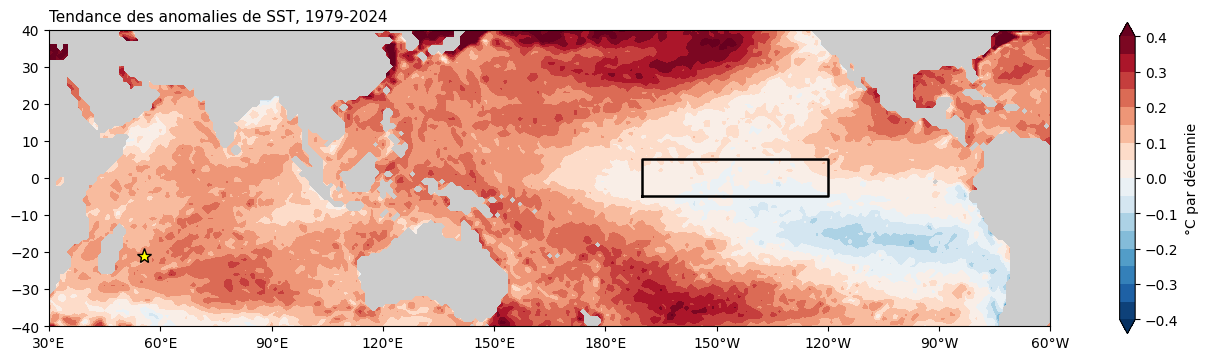

Tendance moyenne entre 40°S et 40°N (30°E-60°W) : 0.14 °C/déc.
Tendance au point de grille de La Réunion        : 0.19 °C/déc.
                                         moyenne   max   min
Gulf Stream (33-40°N, 75-60°W)              0.26  0.82 -0.01
Kuroshio (33-40°N, 140-170°E)               0.31  0.75  0.06
Est de l’Australie (40-30°S, 150-190°E)     0.23  0.43  0.05
Pacifique ouest (0-20°N, 120-160°E)         0.19  0.28  0.05
Niño3.4                                     0.01  0.10 -0.10
Pacifique sud-est (40-20°S, 100-70°W)       0.00  0.18 -0.29
Autour de La Réunion (23-19°S, 53-58°E)     0.17  0.21  0.12 



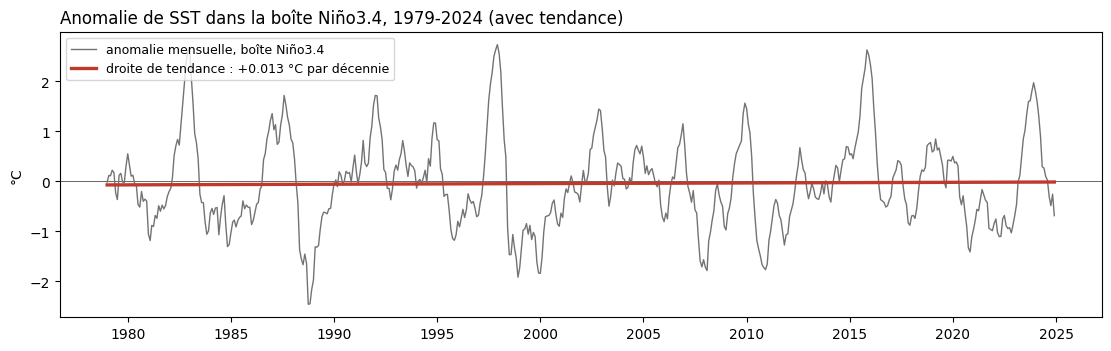

Pente : +0.0013 °C/an = +0.013 °C par décennie ; droite de -0.070 °C (janv. 1979) à -0.012 °C (déc. 2024)
Moyenne des écarts à la droite : -8.2e-17 °C


In [15]:
# 3.1 Carte de la tendance des anomalies, en °C par décennie
trend = linear_trend(sst_a) * 10                   # °C par an -> °C par décennie (× 10 ans)
fig = plot_global([trend], ['Tendance des anomalies de SST, 1979-2024'],
                  levels=np.arange(-0.4, 0.41, 0.05), cmap='RdBu_r', label='°C par décennie')
plt.show()
print('Tendance moyenne entre 40°S et 40°N (30°E-60°W) :',
      round(float(area_mean(trend, lat=(-40, 40), lon=(30, 300))), 2), '°C/déc.')
print('Tendance au point de grille de La Réunion        :', round(float(at(trend, 'La Réunion')), 2), '°C/déc.')
REG_T = {'Gulf Stream (33-40°N, 75-60°W)': dict(lat=(33, 40), lon=(285, 300)),
         'Kuroshio (33-40°N, 140-170°E)': dict(lat=(33, 40), lon=(140, 170)),
         'Est de l’Australie (40-30°S, 150-190°E)': dict(lat=(-40, -30), lon=(150, 190)),
         'Pacifique ouest (0-20°N, 120-160°E)': dict(lat=(0, 20), lon=(120, 160)),
         'Niño3.4': NINO34,
         'Pacifique sud-est (40-20°S, 100-70°W)': dict(lat=(-40, -20), lon=(260, 290)),
         'Autour de La Réunion (23-19°S, 53-58°E)': dict(lat=(-23, -19), lon=(53, 58))}
sub = lambda v: trend.sel(lat=slice(*v['lat']), lon=slice(*v['lon']))
print(pd.DataFrame({'moyenne': {k: round(float(area_mean(trend, **v)), 2) for k, v in REG_T.items()},
                    'max': {k: round(float(sub(v).max()), 2) for k, v in REG_T.items()},
                    'min': {k: round(float(sub(v).min()), 2) for k, v in REG_T.items()}}), '\n')

# 3.2 Anomalie moyenne dans la boîte Niño3.4, mois par mois, et sa droite de tendance
box_a = area_mean(sst_a, **NINO34)                 # une valeur par mois, °C, AVEC tendance
b = float(linear_trend(box_a))                     # pente, °C par an
line = box_a.mean() + linear_trend(box_a) * _years(box_a)   # la droite : ȳ + b (t - t̄)

fig, ax = plt.subplots(figsize=(11, 3.4), constrained_layout=True)
ax.plot(box_a.time, box_a, color='0.45', lw=1, label='anomalie mensuelle, boîte Niño3.4')
ax.plot(box_a.time, line, color='#c0392b', lw=2.4, zorder=3, label=f'droite de tendance : {10 * b:+.3f} °C par décennie')
ax.axhline(0, color='0.3', lw=0.6, zorder=1)
ax.set_ylabel('°C'); ax.legend(loc='upper left', fontsize=9)
ax.set_title('Anomalie de SST dans la boîte Niño3.4, 1979-2024 (avec tendance)', loc='left')
plt.show()
print(f'Pente : {b:+.4f} °C/an = {10 * b:+.3f} °C par décennie ; '
      f'droite de {float(line[0]):+.3f} °C (janv. 1979) à {float(line[-1]):+.3f} °C (déc. 2024)')
print(f'Moyenne des écarts à la droite : {float((box_a - line).mean()):.1e} °C')

*Checks and answers:*

* **Carte.** La mer se réchauffe presque partout : +0,14 °C par décennie en moyenne entre 40°S et 40°N. Le réchauffement le plus fort est aux moyennes latitudes de l'hémisphère nord, le long des grands courants chauds de bord ouest : le Gulf Stream au large des États-Unis (jusqu'à +0,82 °C par décennie) et le Kuroshio au large du Japon (jusqu'à +0,75). Il est fort aussi à l'est de l'Australie vers 30–40°S (jusqu'à +0,43) et dans le Pacifique ouest (+0,19 en moyenne). À l'inverse, le Pacifique est se réchauffe peu : la boîte Niño3.4 est presque plate (+0,01), et le Pacifique sud-est ne se réchauffe pas en moyenne, avec un refroidissement au large du Chili (jusqu'à −0,29 °C par décennie). *Autour de La Réunion* : +0,17 à +0,19 °C par décennie, soit environ +0,8 à +0,9 °C sur 1979–2024, plus que la moyenne tropicale.
* **Série de la boîte.** Pente : **+0,013 °C par décennie** (+0,0013 °C par an). La droite va de −0,07 °C en 1979 à −0,01 °C en 2024.
* **Pourquoi retirer la tendance.** Les anomalies sont calculées par rapport à une période fixe (1991–2020). Avec le réchauffement, elles sont tirées vers le positif en fin de série et vers le négatif au début. On classerait alors en « El Niño » des années seulement parce qu'elles sont récentes, et en « La Niña » des années anciennes. Or on veut repérer l'oscillation naturelle : une boîte plus chaude ou plus froide que la normale *de son époque*, pas le changement climatique. Ici la tendance de Niño3.4 est faible, mais autour de La Réunion elle est 15 fois plus forte : en partie 2, il faudra aussi éviter de mélanger tendance et ENSO.
* **Vérification.** La droite passe bien au milieu de la série (moyenne des écarts à la droite nulle) ✓. La pente est de l'ordre du centième de degré par décennie, bien en dessous du dixième ✓.

## Part 1, step 4 — Removing the trend

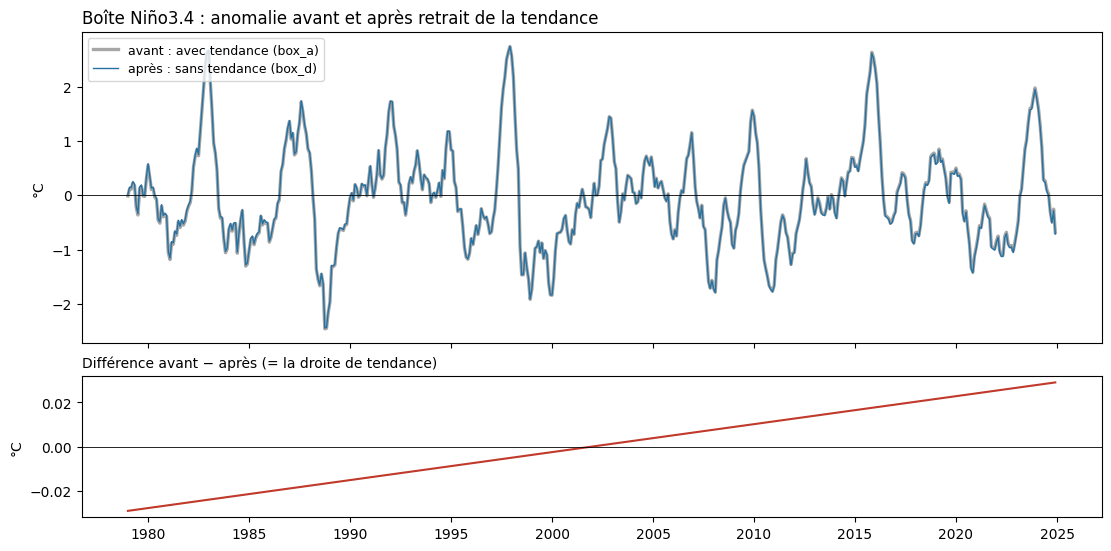

Pente de la boîte après retrait : 3.7e-11 °C par décennie
Plus grand écart avant / après : 0.029 °C

Pente 1979-2023 : +0.001 °C/déc. ; 1979-2024 : +0.013 °C/déc.
En ajoutant 2024, les valeurs 1979-2023 de la série sans tendance bougent de 0.027 °C au plus


In [16]:
# 4.1 Retirer la tendance en chaque point de grille, puis la série de la boîte avant / après
sst_d = remove_trend(sst_a)
box_d = area_mean(sst_d, **NINO34)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.4), constrained_layout=True, sharex=True,
                         gridspec_kw={'height_ratios': [2.2, 1]})
axes[0].plot(box_a.time, box_a, color='0.65', lw=2.4, label='avant : avec tendance (box_a)')
axes[0].plot(box_d.time, box_d, color='#2471a3', lw=1, label='après : sans tendance (box_d)')
axes[0].axhline(0, color='k', lw=0.6); axes[0].set_ylabel('°C'); axes[0].legend(loc='upper left', fontsize=9)
axes[0].set_title('Boîte Niño3.4 : anomalie avant et après retrait de la tendance', loc='left')
axes[1].plot(box_a.time, box_a - box_d, color='#c0392b', lw=1.5)
axes[1].axhline(0, color='k', lw=0.6); axes[1].set_ylabel('°C')
axes[1].set_title('Différence avant − après (= la droite de tendance)', loc='left', fontsize=10)
plt.show()
print(f'Pente de la boîte après retrait : {10 * float(linear_trend(box_d)):.1e} °C par décennie')
print(f'Plus grand écart avant / après : {float(abs(box_a - box_d).max()):.3f} °C')

# 4.2 Ajouter une année change la droite. Test : droite ajustée sur 1979-2023, puis sur 1979-2024
past = box_a.sel(time=slice(None, '2023-12-01'))
change = remove_trend(box_a).sel(time=past.time) - remove_trend(past)
print(f'\nPente 1979-2023 : {10 * float(linear_trend(past)):+.3f} °C/déc. ; '
      f'1979-2024 : {10 * float(linear_trend(box_a)):+.3f} °C/déc.')
print(f'En ajoutant 2024, les valeurs 1979-2023 de la série sans tendance bougent de {float(abs(change).max()):.3f} °C au plus')

*Checks and answers:*

* **Avant / après.** Les deux courbes se superposent presque. La tendance de la boîte étant minuscule, retirer la droite change chaque valeur de 0,03 °C au plus : −0,03 °C en 1979 et +0,03 °C en 2024. La différence entre les deux séries est exactement la droite b (t − t̄).
* **Si l'on ajoute 2025.** La droite est recalculée sur toute la période (nouvelle pente b, nouveau temps moyen t̄). Donc **toutes les valeurs passées de l'indice changent**, pas seulement la dernière. Test fait ici en ajoutant 2024 à la période 1979–2023 : la pente passe de +0,001 à +0,013 °C par décennie, et les valeurs passées bougent jusqu'à 0,03 °C. C'est peu (3 % d'un écart-type), mais une année proche du seuil ±1 pourrait changer de classe. Les années aux extrémités pèsent le plus sur la pente : ici, l'El Niño de 2023-24. Un indice sans tendance dépend donc de la période choisie et doit être recalculé à chaque mise à jour.
* **Vérification.** Pente de la boîte après retrait : quelques 10⁻¹¹ °C par décennie, simple bruit d'arrondi, donc 0 ✓.

## Part 1, step 5 — Mean over the box

In [17]:
# 5.1 Boîte Niño3.4 : moyenne pondérée par cos(latitude), et moyenne simple
box_w = area_mean(sst_d, **NINO34)                    # pondérée (par défaut)
box_u = area_mean(sst_d, **NINO34, weighted=False)    # simple
diff = abs(box_w - box_u)
print(f'Niño3.4 : plus grand |pondérée − simple| = {float(diff.max()):.4f} °C '
      f'({str(diff.idxmax("time").values)[:7]}) ; en moyenne {float(diff.mean()):.4f} °C')

# 5.2 Même test pour une boîte vers 30°S (37-27°S, 55-65°E)
SOUTH = dict(lat=(-37, -27), lon=(55, 65))
s_w = area_mean(sst_d, **SOUTH)
s_u = area_mean(sst_d, **SOUTH, weighted=False)
diff_s = abs(s_w - s_u)
print(f'Boîte 30°S : plus grand |pondérée − simple| = {float(diff_s.max()):.4f} °C '
      f'({str(diff_s.idxmax("time").values)[:7]}) ; en moyenne {float(diff_s.mean()):.4f} °C')

for name, bx in [('Niño3.4', NINO34), ('30°S', SOUTH)]:
    c = np.cos(np.deg2rad(sst.sel(lat=slice(*bx['lat'])).lat))
    print(f'cos φ dans la boîte {name} : de {float(c.min()):.3f} à {float(c.max()):.3f}')
raw = sst.sel(lat=slice(-37, -27), lon=slice(55, 65)).mean(['lon', 'time'])
print(f'Boîte 30°S, SST brute : {float(raw.sel(lat=-27) - raw.sel(lat=-37)):.1f} °C plus chaude au nord qu’au sud ; '
      f'pondérée − simple = {float((area_mean(sst, **SOUTH) - area_mean(sst, **SOUTH, weighted=False)).mean()):+.3f} °C en moyenne')

box = box_w     # la série de la boîte (°C, sans tendance) : on garde la moyenne pondérée, la vraie moyenne par surface

Niño3.4 : plus grand |pondérée − simple| = 0.0012 °C (1998-07) ; en moyenne 0.0002 °C
Boîte 30°S : plus grand |pondérée − simple| = 0.0302 °C (1997-02) ; en moyenne 0.0050 °C
cos φ dans la boîte Niño3.4 : de 0.996 à 1.000
cos φ dans la boîte 30°S : de 0.799 à 0.891
Boîte 30°S, SST brute : 6.4 °C plus chaude au nord qu’au sud ; pondérée − simple = +0.072 °C en moyenne


*Checks and answers:*

* **Niño3.4.** Le plus grand écart entre moyenne pondérée et moyenne simple est de 0,0012 °C (juillet 1998), 0,0002 °C en moyenne : négligeable ✓. Dans la boîte, cos φ ne varie que de 0,996 à 1 : toutes les mailles ont presque la même surface.
* **Boîte vers 30°S.** Le plus grand écart est de 0,030 °C (février 1997), 0,005 °C en moyenne, soit environ 25 fois plus. **Pourquoi** : entre 27°S et 37°S, cos φ passe de 0,891 à 0,799, donc les mailles du nord de la boîte sont environ 12 % plus grandes que celles du sud. Et la mer n'est pas la même au nord et au sud de la boîte : sur la SST brute, 6,4 °C plus chaude à 27°S qu'à 37°S, la moyenne pondérée est en moyenne 0,07 °C plus chaude que la moyenne simple. Plus la boîte est loin de l'équateur et étendue en latitude, plus la pondération compte.
* On garde la moyenne pondérée, qui est la vraie moyenne par surface : `box = box_w`.

## Part 1, step 6 — Standardise, then check your index

1 écart-type = 0.89 °C ; indice : moyenne = 3.1e-17, écart-type = 1.000

a) Avec tendance, en °C : r = 0.982 ; écart moyen (ERA5 − NOAA) = -0.069 °C
   NOAA ramenée à 1991-2020 : écart moyen = -0.010 °C ; la boîte NOAA était +0.06 °C plus chaude en 1991-2020 qu’en 1981-2010
b) Indices finaux (sans tendance, standardisés) : r = 0.984
   écart quadratique moyen entre les deux indices, 1979-1984 : 0.30 écart-type
   écart quadratique moyen entre les deux indices, 2000-2024 : 0.13 écart-type


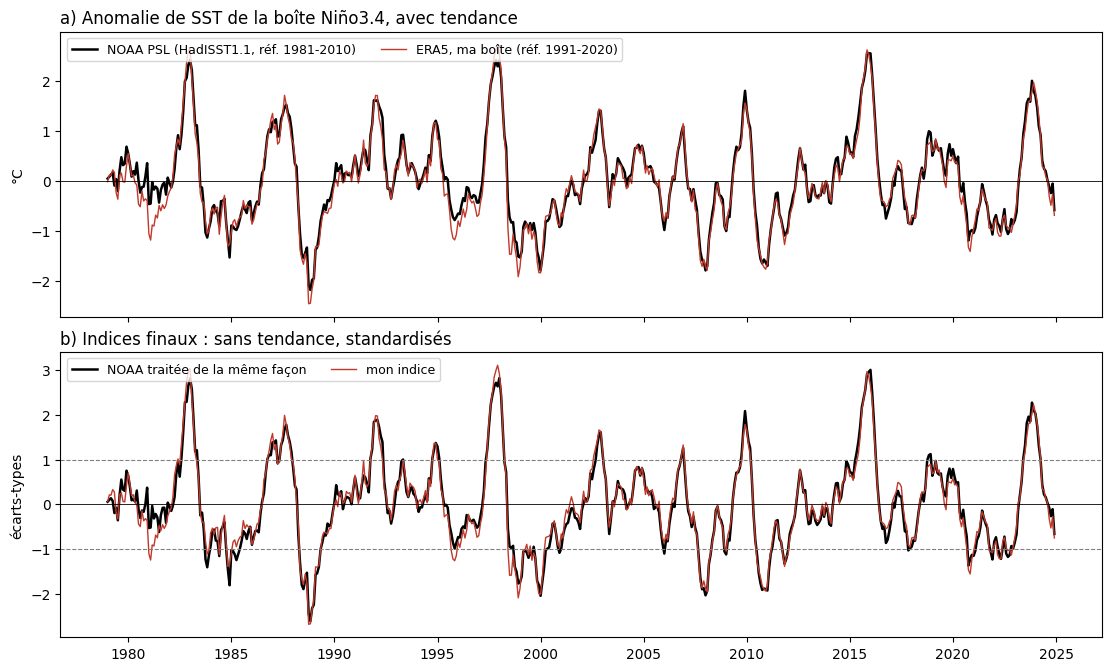


DJF les plus forts, mon indice : 1997-98 (+2.84), 1982-83 (+2.80), 2015-16 (+2.61), 2023-24 (+2.02), 1991-92 (+1.91)
DJF les plus forts, NOAA       : 2015-16 (+2.81), 1982-83 (+2.68), 1997-98 (+2.63), 2023-24 (+1.96), 1991-92 (+1.87)

NINO : 360 mois (1991-01 à 2020-12), moyenne +0.04, écart-type 0.97
Années El Niño (DJF, z ≥ +1) : [1992, 1998, 2010, 2016] | années La Niña (z ≤ −1) : [1999, 2000, 2008, 2011]


In [18]:
# 6.1 Écart-type de la série de la boîte, puis standardisation
sigma = float(box.std())
nino = (box - box.mean()) / box.std()                # indice standardisé, en écarts-types (sans unité)
print(f'1 écart-type = {sigma:.2f} °C ; indice : moyenne = {float(nino.mean()):.1e}, écart-type = {float(nino.std()):.3f}')

# 6.2 Comparaison avec la NOAA, 1979-2024
noaa = load_noaa().sel(time=slice('1979-01-01', '2024-12-01'))    # °C, réf. 1981-2010, avec tendance
#  a) mon anomalie de boîte AVEC tendance (°C) contre la NOAA (°C)
print(f'\na) Avec tendance, en °C : r = {corr(box_a, noaa):.3f} ; '
      f'écart moyen (ERA5 − NOAA) = {float((box_a - noaa).mean()):+.3f} °C')
noaa_9120 = anomalies(noaa)                          # NOAA ramenée à notre référence 1991-2020
print(f'   NOAA ramenée à 1991-2020 : écart moyen = {float((box_a - noaa_9120).mean()):+.3f} °C ; '
      f'la boîte NOAA était {float(noaa.sel(time=slice(*CLIM)).mean()):+.2f} °C plus chaude en 1991-2020 qu’en 1981-2010')
#  b) mon indice final contre la NOAA traitée de la même façon : réf. 1991-2020, sans tendance, standardisée
noaa_d = remove_trend(noaa_9120)
noaa_z = (noaa_d - noaa_d.mean()) / noaa_d.std()
print(f'b) Indices finaux (sans tendance, standardisés) : r = {corr(nino, noaa_z):.3f}')
gap = nino - noaa_z
for a, z in [('1979', '1984'), ('2000', '2024')]:
    print(f'   écart quadratique moyen entre les deux indices, {a}-{z} : '
          f'{float(np.sqrt((gap.sel(time=slice(a, z)) ** 2).mean())):.2f} écart-type')

fig, axes = plt.subplots(2, 1, figsize=(11, 6.6), constrained_layout=True, sharex=True)
axes[0].plot(noaa.time, noaa, color='k', lw=1.8, label='NOAA PSL (HadISST1.1, réf. 1981-2010)')
axes[0].plot(box_a.time, box_a, color='#c0392b', lw=1, label='ERA5, ma boîte (réf. 1991-2020)')
axes[0].set_ylabel('°C'); axes[0].set_title('a) Anomalie de SST de la boîte Niño3.4, avec tendance', loc='left')
axes[1].plot(noaa_z.time, noaa_z, color='k', lw=1.8, label='NOAA traitée de la même façon')
axes[1].plot(nino.time, nino, color='#c0392b', lw=1, label='mon indice')
for v in (1, -1):
    axes[1].axhline(v, color='0.5', lw=0.8, ls='--')
axes[1].set_ylabel('écarts-types'); axes[1].set_title('b) Indices finaux : sans tendance, standardisés', loc='left')
for ax in axes:
    ax.axhline(0, color='k', lw=0.6); ax.legend(loc='upper left', fontsize=9, ncol=2)
plt.show()

# 6.3 Les valeurs DJF les plus fortes (DJF 1997-98 est étiqueté 1998)
def top5(ix):
    djf = seasonal(ix, 'DJF')
    s = djf.sortby(djf, ascending=False)
    return ', '.join(f'{y - 1}-{str(y)[2:]} ({v:+.2f})' for y, v in zip(s.year.values[:5], s.values[:5]))
print('\nDJF les plus forts, mon indice :', top5(nino))
print('DJF les plus forts, NOAA       :', top5(noaa_z))

# 6.4 Garder l'indice sur 1991-2020 sous le nom NINO (il sert en partie 2)
NINO = nino.sel(time=slice(*CLIM))
print(f'\nNINO : {NINO.sizes["time"]} mois ({str(NINO.time.values[0])[:7]} à {str(NINO.time.values[-1])[:7]}), '
      f'moyenne {float(NINO.mean()):+.2f}, écart-type {float(NINO.std()):.2f}')
pos, neg = phase_years(seasonal(NINO, 'DJF'))
print('Années El Niño (DJF, z ≥ +1) :', pos, '| années La Niña (z ≤ −1) :', neg)
NINO.to_series().rename('NINO').to_csv(f'{ROOT}/mon_indice_NINO_1991-2020.csv')   # copie de secours dans le Drive

*Checks and answers:*

* **1 écart-type = 0,89 °C** : un indice de +1 correspond à une boîte Niño3.4 environ 0,9 °C plus chaude que la normale. Après standardisation : moyenne 0, écart-type 1 ✓.
* **a) Avec tendance, en °C** : r = 0,982 ; écart moyen (ERA5 − NOAA) = −0,07 °C. **D'où vient cet écart** : surtout de la période de référence. La NOAA compare à 1981–2010 et nous à 1991–2020, or la boîte était en moyenne 0,06 °C plus chaude en 1991–2020 qu'en 1981–2010 : nos anomalies sont donc plus basses d'autant. Une fois la NOAA ramenée à 1991–2020, l'écart moyen tombe à −0,01 °C. Le reste vient des jeux de données (ERA5 contre HadISST1.1 : observations, interpolation et grille différentes).
* **b) Indices finaux** (référence 1991–2020, sans tendance, standardisés) : r = **0,984**, au-delà de 0,95 ✓. Les deux courbes se superposent. Les écarts sont plus grands au début de la série (0,30 écart-type en moyenne quadratique sur 1979–1984, contre 0,13 après 2000), quand les observations de la mer étaient plus rares, et au pic de 1997-98.
* **Les trois DJF les plus forts** : 1997-98 (+2,84), 1982-83 (+2,80) et 2015-16 (+2,61) ✓, les trois « super El Niño ». Viennent ensuite 2023-24 (+2,02) et 1991-92 (+1,91). La NOAA trouve les mêmes trois, mais dans l'ordre 2015-16, 1982-83, 1997-98 : le classement des très grands événements dépend du jeu de données.
* **NINO** = l'indice sur 1991–2020 : 360 mois, de moyenne +0,04 et d'écart-type 0,97 sur cette période (proches de 0 et 1, car l'indice a été standardisé sur 1979–2024). En DJF, les années El Niño (z ≥ +1) sont 1992, 1998, 2010 et 2016 ; les années La Niña (z ≤ −1) sont 1999, 2000, 2008 et 2011. Ce sont bien des épisodes connus ✓. Il n'y aura donc que 4 années de chaque phase pour les comparaisons de la partie 2. Une copie de NINO est enregistrée dans le Drive (`mon_indice_NINO_1991-2020.csv`).

## Hypothesis (Part 1, step H) — Hypothèse

*Écrite avant de mesurer quoi que ce soit sur l'irradiation (partie 2).*

1. En été austral (DJF) d'une année El Niño, l'irradiation à La Réunion sera **un peu plus forte** que la normale.
2. Mécanisme : El Niño décale la circulation de Walker vers l'est, ce qui renforce l'air descendant (subsidence) sur l'océan Indien et l'Afrique australe, comme le montrent les étés secs d'Afrique australe et de Madagascar en année El Niño ; il y aurait donc moins de nuages et plus de soleil sur l'île.
3. Ordre de grandeur : **environ +2 %** (entre +1 et +3 %) par rapport à une année normale, soit du même ordre que la variabilité d'une année à l'autre trouvée au TP2 (CV de quelques %), si bien que l'effet risque d'être difficile à distinguer du « bruit », avec seulement 4 étés El Niño sur 1991–2020 pour le mesurer.

## Part 2, A — From raw irradiation to the La Réunion-Mauritius box (steps 1 to 5)

Frozen({'time': 360, 'lat': 131, 'lon': 241}) | min 0.8 | max 20.63 m/s


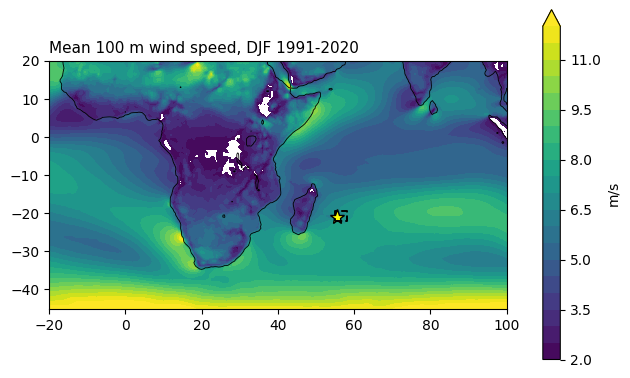

Mean DJF wind in the box: 6.75 m/s
Seasonal cycle of the box (m/s): {1: 6.88, 2: 7.09, 3: 7.21, 4: 7.39, 5: 7.34, 6: 8.31, 7: 8.83, 8: 8.44, 9: 7.74, 10: 7.2, 11: 6.36, 12: 6.35}
Weakest month: 12 (6.35 m/s) | strongest: 7 (8.83 m/s) | amplitude 2.48 m/s


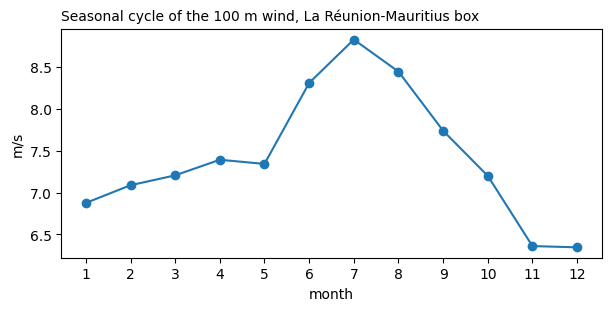

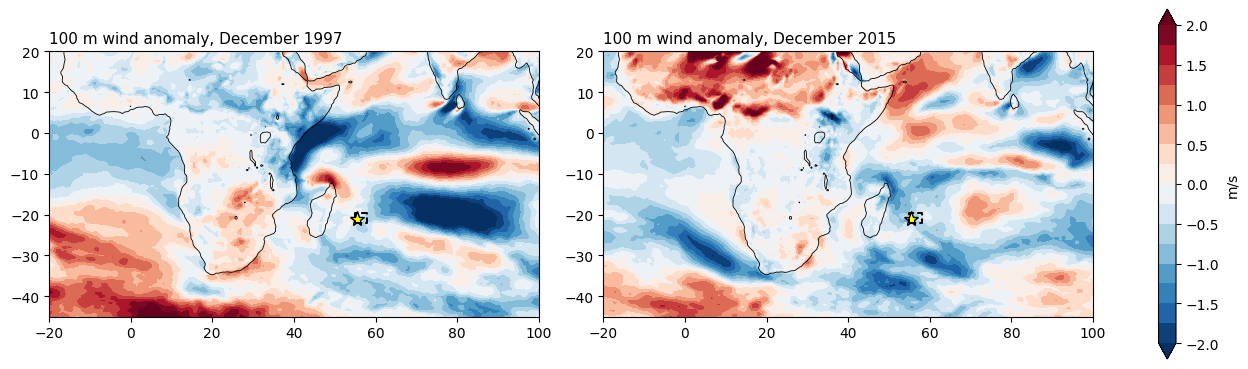

Box anomaly Dec 1997: -0.3 m/s | Dec 2015: -0.56 m/s
Check, mean anomaly of each calendar month in the box (should be ~0): 1.6293125585746063e-07


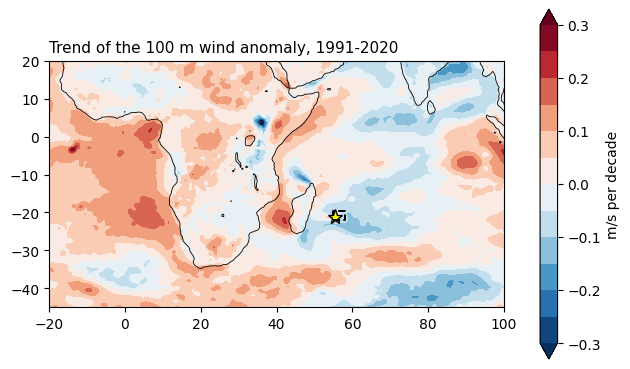

Trend of the box: -0.055 m/s per decade
Weighted - simple, max |difference|: 0.0012 m/s
Std of gw: 0.533 m/s (7.9 % of the DJF mean)
Number of summers: 29


In [10]:
# ===== Part 2, A — wind group: from the raw 100 m wind to the box series gw =====
# If NINO is not in memory (Part 1 not re-run), build it from the NOAA file, as the sheet says
if 'NINO' not in globals():
    noaa = load_noaa().sel(time=slice('1979-01-01', '2024-12-31'))
    noaa_d = remove_trend(noaa)
    NINO = ((noaa_d - noaa_d.mean()) / noaa_d.std()).sel(time=slice(*CLIM))

# A.1 Raw data
wind = open_monthly('ws100_mon_*.nc', 'ws100')          # m/s, no conversion
print(wind.sizes, '| min', round(float(wind.min()), 2), '| max', round(float(wind.max()), 2), 'm/s')

wind_djf = seasonal(wind, 'DJF').mean('year')           # mean DJF map 1991-2020
fig = plot_maps([wind_djf], ['Mean 100 m wind speed, DJF 1991-2020'], np.arange(2, 12.01, 0.5),
                cmap='viridis', label='m/s', extend='max', ncols=1)
fig.savefig('A1_wind_DJF_mean.png', dpi=200, bbox_inches='tight'); plt.show()
print('Mean DJF wind in the box:', round(float(area_mean(wind_djf, **MASC)), 2), 'm/s')

cyc = area_mean(climatology(wind), **MASC)              # seasonal cycle of the box (12 values)
print('Seasonal cycle of the box (m/s):', dict(zip(cyc.month.values.tolist(), cyc.round(2).values.tolist())))
print(f'Weakest month: {int(cyc.idxmin())} ({float(cyc.min()):.2f} m/s) | strongest: {int(cyc.idxmax())} ({float(cyc.max()):.2f} m/s)'
      f' | amplitude {float(cyc.max() - cyc.min()):.2f} m/s')
fig, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)
ax.plot(cyc.month, cyc, marker='o'); ax.set_xticks(range(1, 13)); ax.set_xlabel('month'); ax.set_ylabel('m/s')
ax.set_title('Seasonal cycle of the 100 m wind, La Réunion-Mauritius box', loc='left', fontsize=10)
fig.savefig('A1_wind_cycle.png', dpi=200, bbox_inches='tight'); plt.show()

# A.2 Anomalies
wind_a = anomalies(wind)
fig = plot_maps([wind_a.sel(time='1997-12-01'), wind_a.sel(time='2015-12-01')],
                ['100 m wind anomaly, December 1997', '100 m wind anomaly, December 2015'],
                np.arange(-2, 2.01, 0.25), cmap='RdBu_r', label='m/s')
fig.savefig('A2_wind_anom_Dec1997_Dec2015.png', dpi=200, bbox_inches='tight'); plt.show()
print('Box anomaly Dec 1997:', round(float(area_mean(wind_a.sel(time='1997-12-01'), **MASC)), 2),
      'm/s | Dec 2015:', round(float(area_mean(wind_a.sel(time='2015-12-01'), **MASC)), 2), 'm/s')
check = area_mean(wind_a, **MASC).groupby('time.month').mean()
print('Check, mean anomaly of each calendar month in the box (should be ~0):', float(abs(check).max()))

# A.3 Trend, removal, box
trend = linear_trend(wind_a) * 10                        # m/s per decade
fig = plot_maps([trend], ['Trend of the 100 m wind anomaly, 1991-2020'], np.arange(-0.3, 0.31, 0.05),
                cmap='RdBu_r', label='m/s per decade', ncols=1)
fig.savefig('A3_wind_trend.png', dpi=200, bbox_inches='tight'); plt.show()
print('Trend of the box:', round(float(linear_trend(area_mean(wind_a, **MASC)) * 10), 3), 'm/s per decade')

wind_d = remove_trend(wind_a)
gw = seasonal(area_mean(wind_d, **MASC), 'DJF')          # one value per summer
gw_simple = seasonal(area_mean(wind_d, **MASC, weighted=False), 'DJF')
print('Weighted - simple, max |difference|:', round(float(abs(gw - gw_simple).max()), 4), 'm/s')
print(f'Std of gw: {float(gw.std()):.3f} m/s ({100 * float(gw.std()) / float(area_mean(wind_djf, **MASC)):.1f} % of the DJF mean)')
print('Number of summers:', gw.sizes['year'])

*Note : dans la session Colab de la partie 2, l'indice `NINO` a été reconstruit à partir du fichier NOAA (traité comme mon indice : tendance retirée, standardisé), comme la fiche le prévoit. Il donne exactement les mêmes années El Niño et La Niña que mon indice de la partie 1 (corrélation 0,98 entre les deux).*

*Vérifications et réponses (A)*

**A.1 Données brutes.** Le vent à 100 m va de 0,8 à 20,6 m/s : les valeurs sont plausibles, il n'y a pas d'erreur d'unité. Sur la carte DJF, les vents les plus forts sont dans les westerlies au sud de 40°S (> 11 m/s), au large de l'Afrique du Sud-Ouest (courant de Benguela, ~10 m/s) et dans la bande des alizés à l'est de Madagascar et des Mascareignes (7 à 8 m/s). Les plus faibles sont sur les terres (bassin du Congo, Madagascar < 4 m/s) et près de l'équateur. Moyenne DJF de la boîte : **6,75 m/s**. Cycle saisonnier de la boîte : minimum en **décembre (6,35 m/s)**, maximum en **juillet (8,83 m/s)**, soit une amplitude de 2,48 m/s. Les alizés sont plus forts en hiver austral, quand l'anticyclone des Mascareignes est plus fort.

**A.2 Anomalies.** Dans la boîte : **−0,30 m/s en décembre 1997** et **−0,56 m/s en décembre 2015**. Les deux mois ont le même signe dans la boîte, mais les cartes ne se ressemblent pas. En 1997, il y a une forte baisse des alizés entre 10 et 25°S de 60 à 100°E (< −2 m/s) et une hausse vers 10°S. En 2015, les anomalies sont plus faibles et plus éparses autour des Mascareignes. Deux El Niño forts ne donnent donc pas le même vent. Vérification : la moyenne des anomalies de chaque mois calendaire dans la boîte vaut 1,6·10⁻⁷ m/s ≈ 0, donc le cycle saisonnier a bien été retiré.

**A.3 Tendance.** Tendance de la boîte : **−0,055 m/s par décennie**, soit −0,17 m/s en 30 ans. C'est faible devant l'écart-type des étés (0,53 m/s). La carte montre une légère baisse sur l'océan au sud-est de Madagascar et une hausse sur l'Atlantique tropical. Écart pondéré − simple : **0,001 m/s**, négligeable (la boîte ne fait que 2,5° en latitude). Écart-type de gw : **0,53 m/s (7,9 % de la moyenne DJF)**.

*Pourquoi retirer la tendance ici et la garder en D ?* Ici, on cherche le lien avec ENSO d'une année sur l'autre : une tendance lente (changement climatique, dérive des données) pourrait créer ou masquer une corrélation sans rapport avec ENSO. En D, on calcule la production d'un parc éolien, qui produit avec le vent réel, tendance et cycle saisonnier compris.

## Part 2, B — The link with your index

El Niño summers: [1992, 1998, 2010, 2016] | La Niña summers: [1999, 2000, 2008, 2011]


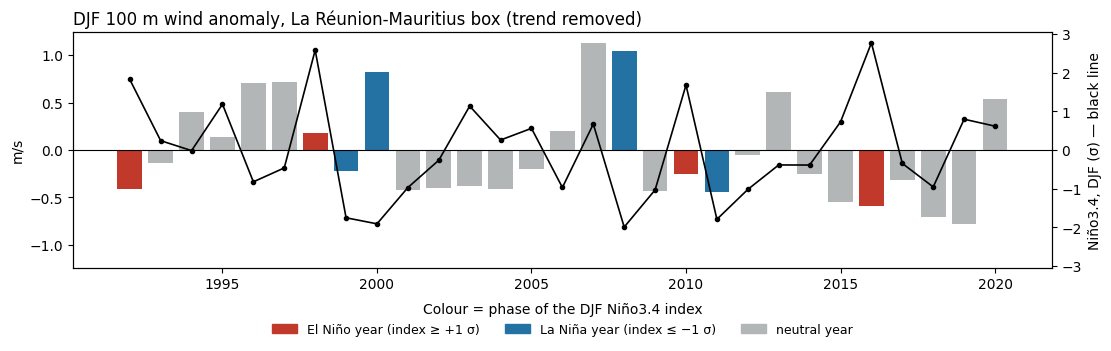

gw in El Niño summers (m/s): [-0.41, 0.18, -0.26, -0.59]
gw in La Niña summers (m/s): [-0.22, 0.82, 1.04, -0.45]
3 weakest summers: [2019, 2018, 2016] | 3 windiest: [2000, 2008, 2007]
r = -0.24 | threshold (n = 29) = 0.37 | r² = 6 % | significant at 5 %: False


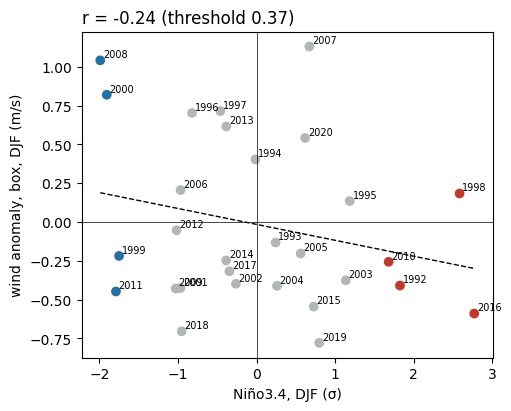

In [11]:
# ===== Part 2, B — link with the index =====
nino = seasonal(NINO, 'DJF')                              # DJF index, one value per summer
pos, neg = phase_years(nino)
print('El Niño summers:', pos, '| La Niña summers:', neg)

fig = plot_bars(gw, nino, 'DJF 100 m wind anomaly, La Réunion-Mauritius box (trend removed)', 'm/s')
fig.savefig('B_wind_bars.png', dpi=200, bbox_inches='tight'); plt.show()
print('gw in El Niño summers (m/s):', gw.sel(year=pos).round(2).values.tolist())
print('gw in La Niña summers (m/s):', gw.sel(year=neg).round(2).values.tolist())
print('3 weakest summers:', gw.sortby(gw).year.values[:3].tolist(), '| 3 windiest:', gw.sortby(gw).year.values[-3:].tolist())

r = corr(gw, nino); n = gw.sizes['year']; rc = r_threshold(n)
print(f'r = {r:.2f} | threshold (n = {n}) = {rc:.2f} | r² = {100 * r**2:.0f} % | significant at 5 %: {abs(r) > rc}')

a, b = xr.align(nino, gw)
fig, ax = plt.subplots(figsize=(5, 4), constrained_layout=True)
col = ['#c0392b' if y in pos else '#2471a3' if y in neg else '#b3b6b7' for y in a.year.values]
ax.scatter(a, b, c=col)
for y, x_, y_ in zip(a.year.values, a.values, b.values):
    ax.annotate(str(y), (x_, y_), fontsize=7, xytext=(2, 2), textcoords='offset points')
p = np.polyfit(a, b, 1); xx = np.linspace(float(a.min()), float(a.max()), 10); ax.plot(xx, np.polyval(p, xx), 'k--', lw=1)
ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
ax.set_xlabel('Niño3.4, DJF (σ)'); ax.set_ylabel('wind anomaly, box, DJF (m/s)')
ax.set_title(f'r = {r:.2f} (threshold {rc:.2f})', loc='left')
fig.savefig('B_wind_scatter.png', dpi=200, bbox_inches='tight'); plt.show()

*Vérifications et réponses (B)*

**Années retenues** (DJF, seuil ±1 σ, 29 étés 1992-2020) : El Niño **1992, 1998, 2010, 2016** ; La Niña **1999, 2000, 2008, 2011** (mêmes années avec l'indice NOAA).

**Barres.** Anomalies de vent en été El Niño : −0,41 (1992), +0,18 (1998), −0,26 (2010) et −0,59 m/s (2016). **3 étés El Niño sur 4 sont sous zéro**, mais pas 1998, pourtant l'El Niño le plus fort. Les 3 étés les moins venteux sont 2019, 2018 et **2016** (El Niño) ; les 3 plus venteux sont **2000** et **2008** (La Niña) et 2007. Les extrêmes vont donc plutôt dans le sens attendu, mais pas de façon systématique : La Niña 1999 (−0,22) et 2011 (−0,45) sont aussi sous zéro.

**Corrélation.** r = **−0,24**, seuil r_threshold(29) = **0,37**, r² = **6 %**. Significatif à 5 % : **non**. Le signe négatif indique des étés El Niño plutôt moins venteux dans la boîte, mais ENSO ne représente que 6 % de la variance du vent d'un été à l'autre. Une corrélation n'est pas une preuve de cause.

**Hypothèse : non tranchée.** Le signe est cohérent avec un affaiblissement des alizés en El Niño, mais |r| < 0,37 : avec 29 étés, on ne peut pas distinguer ce lien du hasard. Cela ne veut pas dire qu'il n'y a pas d'effet, seulement qu'il est faible devant la variabilité naturelle.

## Part 2, C — Map: where does El Niño change the sunshine?

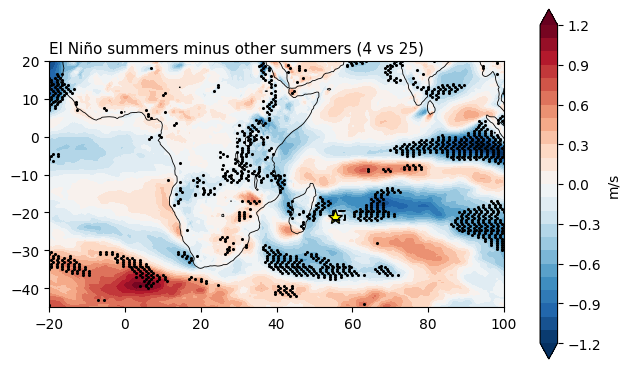

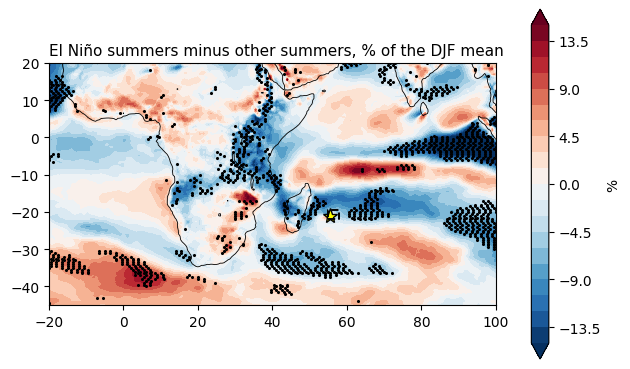

Box: -0.29 m/s (-4.3 %)
Significant grid cells: 12 % of the domain (ocean only: 13 %)
Box cells significant: 2 %
Trade-wind belt 15-30°S (ocean): -0.22 m/s (-2.9 %)
Mozambique Channel: -0.17 m/s (-3.7 %)
East of Madagascar: -0.39 m/s (-6.2 %)
East of the box (60-70°E): -0.69 m/s (-8.7 %)


In [12]:
# ===== Part 2, C — map: where does El Niño change the wind? =====
field = seasonal(wind_d, 'DJF')                           # detrended anomalies, DJF, whole domain
others = [y for y in gw.year.values if y not in pos]      # all the other summers
d, sig = composite(field, pos, others)
d_pct = 100 * d / wind_djf                                # in % of the DJF mean

# two maps, each with its own colour scale
fig = plot_maps([d], [f'El Niño summers minus other summers ({len(pos)} vs {len(others)})'], np.arange(-1.2, 1.21, 0.1),
                cmap='RdBu_r', label='m/s', dots=[sig], ncols=1)
fig.savefig('C_wind_composite_ms.png', dpi=200, bbox_inches='tight'); plt.show()
fig = plot_maps([d_pct], ['El Niño summers minus other summers, % of the DJF mean'], np.arange(-15, 15.1, 1.5),
                cmap='RdBu_r', label='%', dots=[sig], ncols=1)
fig.savefig('C_wind_composite_pct.png', dpi=200, bbox_inches='tight'); plt.show()

box_d = float(area_mean(d, **MASC)); box_pct = 100 * box_d / float(area_mean(wind_djf, **MASC))
print(f'Box: {box_d:+.2f} m/s ({box_pct:+.1f} %)')
print(f'Significant grid cells: {100 * float(sig.mean()):.0f} % of the domain '
      f'(ocean only: {100 * float(sig.where(LSM < 0.5).mean()):.0f} %)')
print(f'Box cells significant: {100 * float(sig.sel(lat=slice(*MASC["lat"]), lon=slice(*MASC["lon"])).mean()):.0f} %')

# Rest of the trade-wind belt, 15-30°S, ocean only, across the whole domain
band = dict(lat=(-30, -15), lon=(float(wind.lon.min()), float(wind.lon.max())))
print(f'Trade-wind belt 15-30°S (ocean): {float(box_mean(d, **band)):+.2f} m/s '
      f'({float(box_mean(d_pct, **band)):+.1f} %)')
for name, (la, lo) in {'Mozambique Channel': ((-25, -15), (36, 44)), 'East of Madagascar': ((-25, -15), (50, 54)),
                       'East of the box (60-70°E)': ((-22, -18), (60, 70))}.items():
    if lo[1] <= float(wind.lon.max()):
        print(f'{name}: {float(box_mean(d, la, lo)):+.2f} m/s ({float(box_mean(d_pct, la, lo)):+.1f} %)')

*Vérifications et réponses (C)*

Composite : moyenne des 4 étés El Niño moins moyenne des 25 autres étés (test de Welch, t_c ≈ 2,8).

1. **Boîte La Réunion–Maurice : −0,29 m/s (−4,3 %), non significatif** : seulement 2 % des mailles de la boîte sont pointées.
2. **Bande des alizés 15–30°S (océan) : −0,22 m/s (−2,9 %) en moyenne.** L'effet le plus fort est une bande d'affaiblissement des alizés vers 18–25°S, de l'est de la boîte jusqu'à 100°E : **−0,69 m/s (−8,7 %) entre 60 et 70°E**, jusqu'à −1 m/s plus à l'est, **significatif** (zone de points cohérente vers 60–80°E). Juste au nord, vers 10°S, le vent **augmente** (+0,3 à +0,6 m/s, significatif) : la bande des alizés semble décalée ou rétrécie.
3. **Est de Madagascar : −0,39 m/s (−6,2 %)** ; **canal du Mozambique : −0,17 m/s (−3,7 %)**, peu de points significatifs.

À noter aussi : un renforcement net des westerlies au sud de l'Afrique (35–45°S, +0,6 à +0,9 m/s, significatif).

Mailles significatives : **12 % du domaine** (13 % sur l'océan), soit plus que les ~5 % attendus par hasard. Les grandes zones de points cohérentes (60–100°E vers 20°S, 10°S, sud de l'Afrique) sont donc crédibles ; les points isolés sur l'Afrique ne le sont pas.

**La boîte est-elle dans une zone d'effet fort ou à la frontière ?** **À la frontière ouest** de la zone d'affaiblissement des alizés. Le signe y est le même (−4 %), mais l'effet est deux fois plus faible qu'à 60–70°E et non significatif.

## Part 2, D — PV production in 2026-27

In [13]:
# Part 2, D is written for the solar groups.
# Wind group: the wind version of D (capacity factor, El Niño deviation, 2026-27 scenario) is in the "wind groups" cell below.

*Activité D écrite pour les groupes solaire : voir la cellule « groupes vent » ci-dessous.*

## Part 2, wind groups — the same chain for the 100 m wind speed

Wind CF, DJF mean: 0.270 | CV: 17.0 % | El Niño summers vs others: -9.0 %
Same deviation for the wind speed: -4.1 %  ->  production / speed ratio: 2.2
CF in El Niño summers: [0.243, 0.291, 0.248, 0.216]
Monthly CF climatology: {1: 0.282, 2: 0.3, 3: 0.311, 4: 0.327, 5: 0.322, 6: 0.402, 7: 0.441, 8: 0.413, 9: 0.356, 10: 0.31, 11: 0.236, 12: 0.235}
Last NOAA value: 2026-07 = +1.90 °C = +2.2 σ


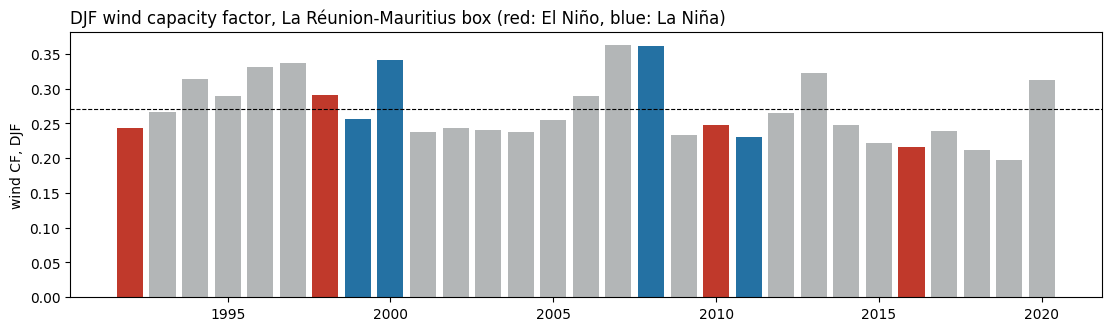

In [14]:
# ===== Part 2, wind groups — D: wind capacity factor and the 2026-27 scenario =====
ws_box = area_mean(wind, **MASC)                          # RAW wind (cycle and trend kept): a farm produces with the real wind
cf = seasonal(wind_cf(ws_box), 'DJF')                     # DJF capacity factor, one value per summer
cf_mean = float(cf.mean())
cf_dev = 100 * (float(cf.sel(year=pos).mean()) - float(cf.sel(year=others).mean())) / cf_mean
cv = 100 * float(cf.std()) / cf_mean
print(f'Wind CF, DJF mean: {cf_mean:.3f} | CV: {cv:.1f} % | El Niño summers vs others: {cf_dev:+.1f} %')

ws_djf = seasonal(ws_box, 'DJF')
ws_dev = 100 * (float(ws_djf.sel(year=pos).mean()) - float(ws_djf.sel(year=others).mean())) / float(ws_djf.mean())
print(f'Same deviation for the wind speed: {ws_dev:+.1f} %  ->  production / speed ratio: {cf_dev / ws_dev:.1f}' if ws_dev else '')
print('CF in El Niño summers:', cf.sel(year=pos).round(3).values.tolist())

# Annual cycle of the CF (to put DJF in context)
cf_cycle = wind_cf(area_mean(climatology(wind), **MASC))
print('Monthly CF climatology:', dict(zip(cf_cycle.month.values.tolist(), cf_cycle.round(3).values.tolist())))

# Scenario 2026-27: last NOAA value, in standard deviations of the Part 1 series
full = load_noaa().dropna('time')
last = full.isel(time=-1)
ref = load_noaa().sel(time=slice('1979-01-01', '2024-12-31'))
print(f"Last NOAA value: {str(last.time.values)[:7]} = {float(last):+.2f} °C = {float(last) / float(ref.std()):+.1f} σ")

fig, ax = plt.subplots(figsize=(11, 3.2), constrained_layout=True)
c = ['#c0392b' if y in pos else '#2471a3' if y in neg else '#b3b6b7' for y in cf.year.values]
ax.bar(cf.year, cf, color=c); ax.axhline(cf_mean, color='k', lw=0.8, ls='--')
ax.set_ylabel('wind CF, DJF'); ax.set_title('DJF wind capacity factor, La Réunion-Mauritius box (red: El Niño, blue: La Niña)', loc='left')
fig.savefig('D_wind_CF.png', dpi=200, bbox_inches='tight'); plt.show()

*Vérifications et réponses (D, groupes vent)*

**Facteur de charge éolien DJF (boîte, vent brut) :** CF moyen **0,27**, coefficient de variation **17 %**. Étés El Niño par rapport aux autres : **−9,0 %** de production, contre **−4,1 %** pour la vitesse. L'écart en production est **2,2 fois** plus grand. En effet, la puissance d'une éolienne varie à peu près comme le cube de la vitesse entre le démarrage (3 m/s) et la puissance nominale (12 m/s) : une petite baisse de vitesse fait perdre beaucoup de production. Le rapport est inférieur à 3, parce qu'une partie du temps le vent est sous 3 m/s ou au-dessus de 12 m/s, où la puissance ne suit pas le cube. Le CF de décembre (0,24) est presque deux fois plus faible que celui de juillet (0,44) : l'été est la saison creuse de l'éolien ici.

**Scénario 2026-2027.** Dernière valeur NOAA : **juillet 2026 = +1,90 °C, soit +2,1 σ de notre série de la partie 1** (1 σ = 0,89 °C). Un El Niño fort se développe. *S'il* se maintient jusqu'en DJF 2026-27, l'été pourrait être un peu moins venteux autour de La Réunion : de l'ordre de −0,3 m/s et **−9 % de production éolienne** en moyenne, avec un effet plus net à l'est des Mascareignes. **Confiance faible** : r² = 6 %, résultat non significatif dans la boîte, seulement 4 étés El Niño en 30 ans, et un El Niño fort ne donne pas toujours un été calme (1998 : +0,18 m/s). Ce n'est pas une prévision.

## Part 2, E — Prepare your oral presentation

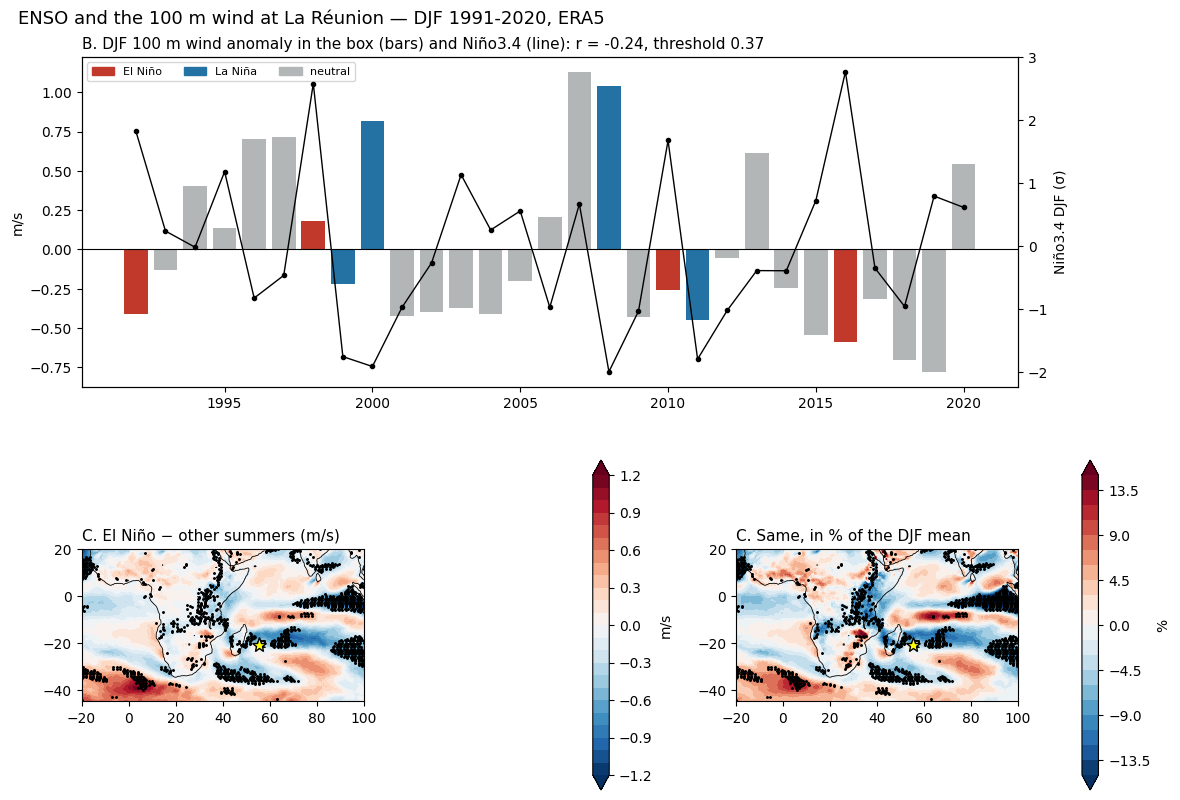

In [15]:
# ===== Part 2, E — one-page support for the oral (figures B and C side by side) =====
from matplotlib.patches import Patch
fig = plt.figure(figsize=(11.7, 8.3), constrained_layout=True)        # A4 landscape
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.25])
ax1 = fig.add_subplot(gs[0, :])
v = gw.to_series(); col = ['#c0392b' if y in pos else '#2471a3' if y in neg else '#b3b6b7' for y in v.index]
ax1.bar(v.index, v.values, color=col); ax1.axhline(0, color='k', lw=0.8); ax1.set_ylabel('m/s')
ax1b = ax1.twinx(); ix = nino.to_series(); ax1b.plot(ix.index, ix.values, 'k-o', ms=3, lw=1); ax1b.set_ylabel('Niño3.4 DJF (σ)')
ax1.set_title(f'B. DJF 100 m wind anomaly in the box (bars) and Niño3.4 (line): r = {r:.2f}, threshold {rc:.2f}', loc='left', fontsize=11)
ax1.legend(handles=[Patch(color='#c0392b', label='El Niño'), Patch(color='#2471a3', label='La Niña'), Patch(color='#b3b6b7', label='neutral')],
           loc='upper left', fontsize=8, ncol=3)
for k, (f, t, lev, lab) in enumerate([(d, 'C. El Niño − other summers (m/s)', np.arange(-1.2, 1.21, 0.1), 'm/s'),
                                      (d_pct, 'C. Same, in % of the DJF mean', np.arange(-15, 15.1, 1.5), '%')]):
    ax = fig.add_subplot(gs[1, k])
    im = ax.contourf(f.lon, f.lat, f, levels=lev, cmap='RdBu_r', extend='both')
    ax.contour(LSM.lon, LSM.lat, LSM, levels=[0.5], colors='k', linewidths=0.6)
    dd = sig.where(sig).stack(p=('lat', 'lon')).dropna('p'); ax.scatter(dd.lon[::3], dd.lat[::3], s=1.2, c='k')
    ax.plot([55, 58, 58, 55, 55], [-22, -22, -19.5, -19.5, -22], 'k--', lw=1.4)
    ax.plot(55.5, -21.1, marker='*', color='k', ms=11, mfc='yellow'); ax.set_aspect('equal')
    ax.set_title(t, loc='left', fontsize=11); fig.colorbar(im, ax=ax, shrink=0.8, label=lab)
fig.suptitle('ENSO and the 100 m wind at La Réunion — DJF 1991-2020, ERA5', fontsize=13, x=0.01, ha='left')
fig.savefig('E_oral_support_wind.png', dpi=200, bbox_inches='tight'); plt.show()

*Schéma complété (groupes vent)*

| | Ce que vous trouvez |
|---|---|
| **A** | moyenne DJF boîte : 6,75 m/s · cycle : de 6,35 m/s (déc.) à 8,83 m/s (juil.) · moyenne des anomalies : 1,6·10⁻⁷ ≈ 0 · tendance : −0,055 m/s/déc. · pondéré − simple : 0,001 m/s · écart-type de gw : 0,53 m/s (7,9 %) |
| **B** | années El Niño : 1992, 1998, 2010, 2016 · r = −0,24 (seuil 0,37) · r² = 6 % · significatif : non |
| **C** | boîte : −0,29 m/s (−4,3 %) · mailles significatives : 12 % · bande des alizés vers 20°S : −0,22 m/s (jusqu'à −0,69 m/s à 60–70°E) |
| **D** | CF éolien DJF : 0,27 · CV : 17 % · étés El Niño : −9 % · Niño3.4, juillet 2026 : +2,1 σ |
| **+** | CF maille : 0,025 · CF boîte : 0,27 |

**Contenu de la page support (figure `E_oral_support_wind.png`)**
1. **Barres (B)** : 3 étés El Niño sur 4 moins venteux que la normale (jusqu'à −0,59 m/s en 2016) ; r = −0,24, sous le seuil de 0,37 (r² = 6 %). **Carte (C)** : affaiblissement significatif des alizés vers 20°S, à l'est des Mascareignes (−0,69 m/s, −8,7 % à 60–70°E) ; dans la boîte, −0,29 m/s (−4,3 %), non significatif.
2. **Hypothèse** : non tranchée. Le signe va dans le sens d'alizés plus faibles en El Niño, mais le lien n'est pas significatif dans la boîte.
3. **Loin de l'île / autour de l'île** : l'effet est plus fort et significatif dans la bande des alizés à l'est (60–100°E) ; la boîte est à sa frontière ouest. Mécanisme possible : en El Niño, la circulation de Walker se déplace et modifie l'anticyclone des Mascareignes, qui s'affaiblit ou se décale. La bande des alizés est alors plus faible vers 20°S et le vent plus fort vers 10°S. À regarder de plus : la pression au niveau de la mer (position et force de l'anticyclone), les composantes u et v du vent, la saison JJA (alizés les plus forts) et le Dipôle de l'océan Indien.
4. **Scénario 2026-27** : Niño3.4 à +2,1 σ en juillet 2026. Si l'El Niño se confirme en DJF, on peut s'attendre à un été un peu moins venteux (~−9 % de production éolienne), avec une confiance faible (r² = 6 %, 4 étés El Niño seulement, et 1998 fait exception).
5. En bas de page : usage de l'IA (code et aide à la rédaction).

## Bonus — P90 years of practical 2 (solar); grid cell versus box (wind)

In [16]:
# ===== Bonus, wind groups — grid cell or box? =====
cf_cell = seasonal(wind_cf(at(wind, 'La Réunion')), 'DJF').mean('year')
cf_box = seasonal(wind_cf(area_mean(wind, **MASC)), 'DJF').mean('year')
cell = at(wind, 'La Réunion')
print(f"La Réunion grid cell: lat {float(cell.lat):.2f}, lon {float(cell.lon):.2f}, "
      f"land fraction {float(at(LSM, 'La Réunion')):.2f}, mean DJF wind {float(seasonal(cell, 'DJF').mean()):.2f} m/s")
print(f'Wind CF, DJF: grid cell {float(cf_cell):.3f} | box {float(cf_box):.3f}')
cf_cell_y = wind_cf(at(wind, 'La Réunion')).groupby('time.year').mean().mean()
cf_box_y = wind_cf(area_mean(wind, **MASC)).groupby('time.year').mean().mean()
print(f'Wind CF, whole year: grid cell {float(cf_cell_y):.3f} | box {float(cf_box_y):.3f}')

La Réunion grid cell: lat -21.00, lon 55.50, land fraction 0.66, mean DJF wind 3.07 m/s
Wind CF, DJF: grid cell 0.025 | box 0.270
Wind CF, whole year: grid cell 0.025 | box 0.326


*Vérifications et réponses (bonus vent)*

CF DJF : **maille de La Réunion 0,025**, **boîte 0,27** (année entière : 0,025 contre 0,33). La maille ERA5 la plus proche de La Réunion est à 66 % terrestre, avec un vent moyen DJF de seulement 3,1 m/s. Le relief de l'île (plus de 3 000 m) y est lissé et la rugosité du sol freine le vent du modèle : le vent tourne autour de la vitesse de démarrage et le CF s'effondre. **Aucun des deux n'est réaliste pour un site précis.** La boîte, surtout océanique, représente l'alizé régional au large : elle est plus proche des sites exposés (crêtes, côte au vent, éolien en mer). La maille sous-estime fortement le vent : aucun parc éolien ne serait construit avec un CF de 2,5 %. Pour un site réel, il faut des mesures ou une descente d'échelle (comme vu au TP2).